In [173]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [174]:
path="https://raw.githubusercontent.com/German-rl/Precios_Marginales_MDA/refs/heads/main/CENACE_PML/data/pml_mda.csv"
df_raw=pd.read_csv(path, index_col=0)
df_raw.head(10)

,hora,pml,pml_ene,pml_per,pml_cng,_nodo,timestamp
fecha,,,,,,,
2022-01-01,1,669.50,636.84,32.66,0.0,01OLI-230,2022-01-01 00:00:00
2022-01-01,2,643.15,612.33,30.83,0.0,01OLI-230,2022-01-01 01:00:00
2022-01-01,3,635.64,605.54,30.10,0.0,01OLI-230,2022-01-01 02:00:00
2022-01-01,4,622.53,594.32,28.22,0.0,01OLI-230,2022-01-01 03:00:00
2022-01-01,5,597.68,571.95,25.73,0.0,01OLI-230,2022-01-01 04:00:00
2022-01-01,6,590.36,566.29,24.08,0.0,01OLI-230,2022-01-01 05:00:00
2022-01-01,7,576.69,553.39,23.30,0.0,01OLI-230,2022-01-01 06:00:00
2022-01-01,8,562.80,540.06,22.73,0.0,01OLI-230,2022-01-01 07:00:00
2022-01-01,9,498.35,473.74,24.61,0.0,01OLI-230,2022-01-01 08:00:00


In [175]:
df_raw.info()

<class 'pandas.DataFrame'>
Index: 254160 entries, 2022-01-01 to 2026-10-31
Data columns (total 7 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   hora       254160 non-null  int64  
 1   pml        254160 non-null  float64
 2   pml_ene    254160 non-null  float64
 3   pml_per    254160 non-null  float64
 4   pml_cng    254160 non-null  float64
 5   _nodo      254160 non-null  str    
 6   timestamp  254160 non-null  str    
dtypes: float64(4), int64(1), str(2)
memory usage: 15.5+ MB


In [176]:
df_raw.rename(columns={'_nodo':'nodo'}, inplace=True)
df_raw.set_index('timestamp', inplace=True)
df_raw.index = pd.to_datetime(df_raw.index)


C:\Users\bestbuy\AppData\Local\Temp\ipykernel_19300\1144390341.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_raw.rename(columns={'_nodo':'nodo'}, inplace=True)
C:\Users\bestbuy\AppData\Local\Temp\ipykernel_19300\1144390341.py:2: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_raw.set_index('timestamp', inplace=True)


In [177]:
df_raw.describe()

,hora,pml,pml_ene,pml_per,pml_cng
count,254160.000000,254160.000000,254160.000000,254160.000000,254160.000000
mean,12.500024,929.717696,842.533608,8.682090,78.502042
std,6.922241,960.490397,728.499784,108.633603,588.759822
min,1.000000,-861.590000,-0.010000,-2430.250000,-8613.620000
25%,6.750000,454.497500,463.437500,-37.200000,-3.380000
50%,12.500000,658.280000,632.775000,8.910000,0.000000
75%,18.250000,1130.490000,1035.832500,45.640000,4.230000
max,25.000000,28965.530000,25590.570000,3374.960000,16189.430000


# Análsis de las variables 
## Análisis por Nodo
Este proyecto se limita al uso de 6 nodos 
|Nodo	|Zona | Tensión KV |
|--- |---|---|
|01OLI-230 Olivar |	CDMX sur | 230 |
|06HUI-230 Huinala |	Monterrey | 230 |
|03SMR-230 San Martín |	Guadalajara | 230 |
|08IZI-115 Itzimná |	Mérida (Península) | 115 |
|05CHU-230 Chuviscar |	Chihuahua (Norte) | 230 |
|02IPO-230 Ixtepec Potencia |	Istmo de Tehuantepec (zona eólica) | 230 |

### PML: Precio Marginal Local ($/MWh) 
Es el precio de la energía eléctrica en un Nodo determinado del Sistema Eléctrico Nacional
se calcula 

**PML = Energía + Pérdidas + Congestión**

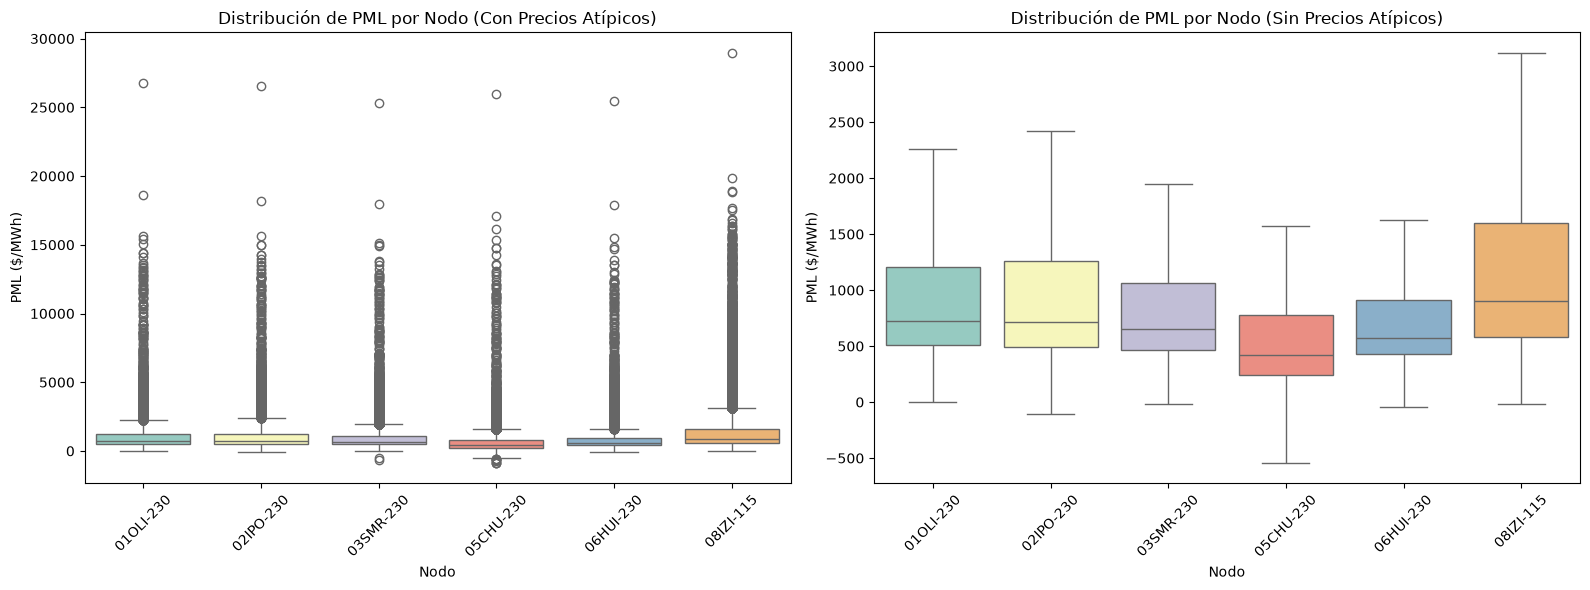

In [178]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
# --- PANEL 1: Con precios atípicos ---
sns.boxplot(x='nodo', hue='nodo', y='pml', data=df_raw, palette='Set3', legend=False, ax=ax1)
ax1.set_title('Distribución de PML por Nodo (Con Precios Atípicos)')
ax1.set_xlabel('Nodo')
ax1.set_ylabel('PML ($/MWh)')
ax1.tick_params(axis='x', rotation=45)
# --- PANEL 2: Sin precios atípicos ---
sns.boxplot(x='nodo', hue='nodo', y='pml', data=df_raw, palette='Set3', legend=False, showfliers=False, ax=ax2)
ax2.set_title('Distribución de PML por Nodo (Sin Precios Atípicos)')
ax2.set_xlabel('Nodo')
ax2.set_ylabel('PML ($/MWh)')
ax2.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

### PML_ene : Precio Marginal Local de la Energía
El componente de energía es el costo marginal de la energía en un punto de referencia del sistema, es decir, lo que cuesta atender un MWh adicional de demanda ignorando la congestión y las pérdidas de la red. Es dependiente del costo de los combustibles y la hora de día, de la demanda, disponibilidad de renovables y oferta de las centrales.  

En una misma hora, el componente de energía es igual para todos los nodos del Sistema Interconectado Nacional; lo que cambia de un nodo a otro son pérdidas y congestión.

### PML_PER: Precio Marginal Local por Pérdida (componente de pérdidas, $/MWh)
 Costo de las pérdidas de energía eléctrica que ocurren al transportar un MWh adicional desde el punto de referencia del sistema hasta el nodo. Depende de la ubicación del nodo en la red y del nivel de demanda: crece cuando la red está más cargada y suele ser mayor en nodos alejados de la generación. Puede ser negativo si un MWh adicional en ese nodo reduce las pérdidas de la red (por ejemplo, un nodo cercano a la generación).

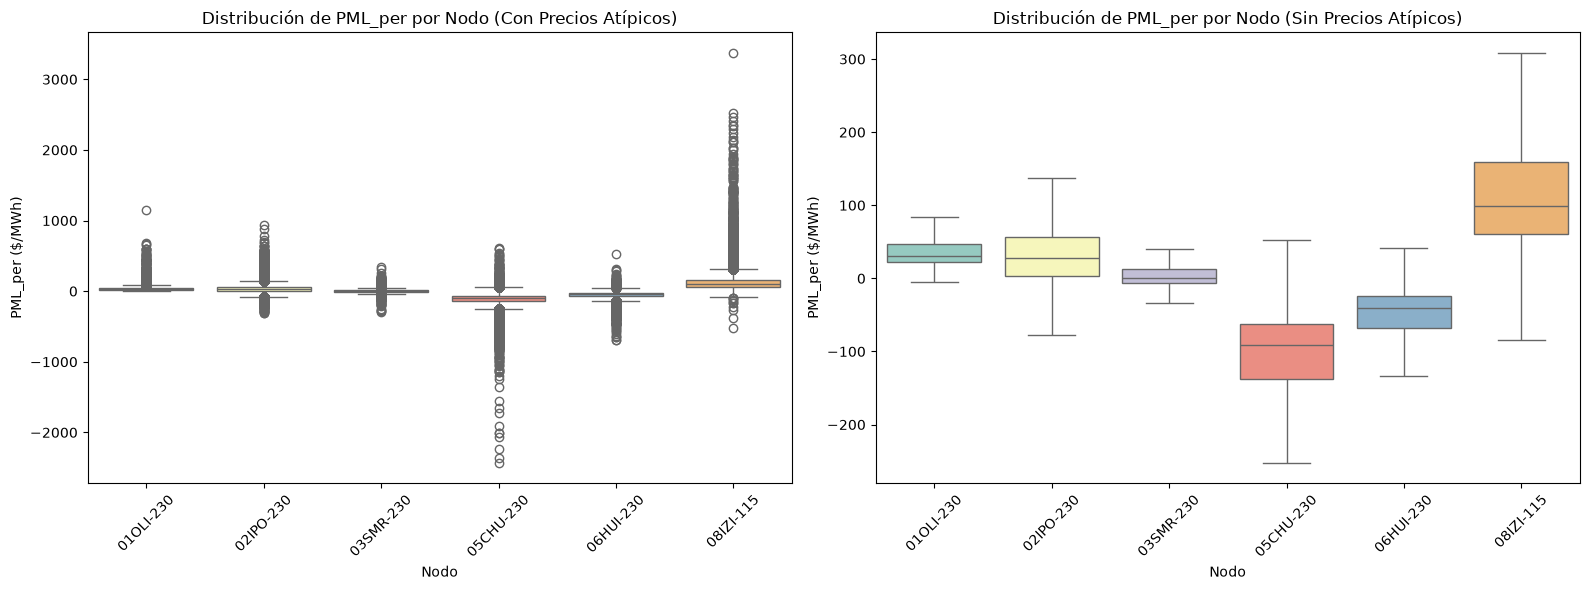

In [179]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
# --- PANEL 1: Con precios atípicos ---
sns.boxplot(x='nodo', hue='nodo', y='pml_per', data=df_raw, palette='Set3', legend=False, ax=ax1)
ax1.set_title('Distribución de PML_per por Nodo (Con Precios Atípicos)')
ax1.set_xlabel('Nodo')
ax1.set_ylabel('PML_per ($/MWh)')
ax1.tick_params(axis='x', rotation=45)
# --- PANEL 2: Sin precios atípicos ---
sns.boxplot(x='nodo', hue='nodo', y='pml_per', data=df_raw, palette='Set3', legend=False, showfliers=False, ax=ax2)
ax2.set_title('Distribución de PML_per por Nodo (Sin Precios Atípicos)')
ax2.set_xlabel('Nodo')
ax2.set_ylabel('PML_per ($/MWh)')
ax2.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

### PML_CNG: Precio Margina Local por Congestión (componente de congestión, $/MWh)
Costo adicional (o ahorro) que aparece cuando los límites de capacidad de las líneas de transmisión impiden que la energía más barata llegue a un nodo. Es cero o cercano a cero cuando no hay restricciones activas. Es positivo en zonas importadoras, donde hay que despachar generación local más cara, y negativo en zonas con exceso de generación barata que no puede salir, como regiones con mucha energía renovable. Es el componente más volátil y el que más diferencia el precio entre nodos.

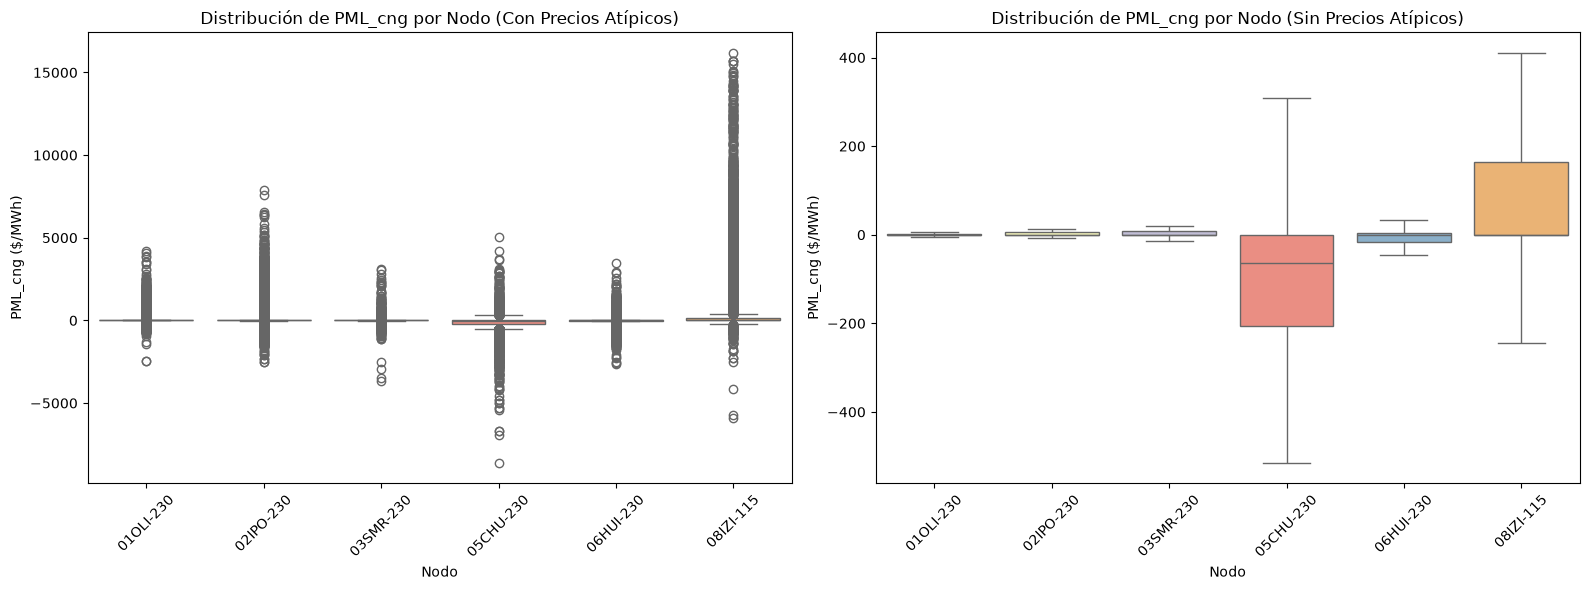

In [180]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
# --- PANEL 1: Con precios atípicos ---
sns.boxplot(x='nodo', hue='nodo', y='pml_cng', data=df_raw, palette='Set3', legend=False, ax=ax1)
ax1.set_title('Distribución de PML_cng por Nodo (Con Precios Atípicos)')
ax1.set_xlabel('Nodo')
ax1.set_ylabel('PML_cng ($/MWh)')
ax1.tick_params(axis='x', rotation=45)
# --- PANEL 2: Sin precios atípicos ---
sns.boxplot(x='nodo', hue='nodo', y='pml_cng', data=df_raw, palette='Set3', legend=False, showfliers=False, ax=ax2)
ax2.set_title('Distribución de PML_cng por Nodo (Sin Precios Atípicos)')
ax2.set_xlabel('Nodo')
ax2.set_ylabel('PML_cng ($/MWh)')
ax2.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

### Tabla comparación Promedio, Mediana y percentiles por nodo 

In [181]:
df=df_raw.copy()
cols = ['pml', 'pml_ene', 'pml_per', 'pml_cng']

# Tabla: promedio, mediana y percentiles por componente y nodo
resumen = (
    df.melt(id_vars='nodo', value_vars=cols,
            var_name='componente', value_name='valor')
      .groupby(['componente', 'nodo'])['valor']
      .agg(promedio='mean',
           mediana='median',
           p10=lambda s: s.quantile(0.10),
           p90=lambda s: s.quantile(0.90),
           p99=lambda s: s.quantile(0.99))
      .round(1)
      .reindex(cols, level='componente')
)
display(resumen)

# % de horas con congestión fuerte (|pml_cng| > 100 $/MWh) por nodo
horas_cng = (
    (df['pml_cng'].abs() > 100)
    .groupby(df['nodo']).mean()
    .mul(100).round(1)
    .rename('% horas con |cng| > 100')
)
display(horas_cng)

# Control de calidad: ¿PML = energía + pérdidas + congestión?
dif = (df['pml'] - (df['pml_ene'] + df['pml_per'] + df['pml_cng'])).abs()
print(f"Filas que no cuadran (> 0.05): {(dif > 0.05).mean():.2%}")

promedio  mediana    p10     p90     p99
componente nodo                                               
pml        01OLI-230     952.4    727.3  417.4  1672.1  3565.9
           02IPO-230     987.4    714.4  386.1  1881.5  4319.9
           03SMR-230     859.6    653.5  382.6  1501.9  3209.6
           05CHU-230     602.3    419.4  116.5  1268.6  2748.7
           06HUI-230     773.1    575.4  351.0  1385.3  3111.4
           08IZI-115    1403.6    900.8  461.4  3002.2  7915.8
pml_ene    01OLI-230     842.5    632.8  382.2  1476.8  3160.9
           02IPO-230     842.5    632.8  382.2  1476.8  3160.9
           03SMR-230     842.5    632.8  382.2  1476.8  3160.9
           05CHU-230     842.5    632.8  382.2  1476.8  3160.9
           06HUI-230     842.5    632.8  382.2  1476.8  3160.9
           08IZI-115     842.5    632.8  382.2  1476.8  3160.9
pml_per    01OLI-230      40.0     30.8   16.1    70.3   181.3
           02IPO-230      35.8     28.1  -20.4    96.5   287.1
           03SMR-230       4.9      1.1  -12.4    28.3    70.2
           05CHU-230    -108.8    -91.8 -206.4   -30.4    73.2
           06HUI-230     -52.4    -41.1 -109.9   -11.0    19.0
           08IZI-115     132.5     98.6   35.8   251.3   712.5
pml_cng    01OLI-230      69.8      0.0   -0.4   200.1  1285.8
           02IPO-230     109.1      0.0   -4.8   353.0  2452.5
           03SMR-230      12.1      0.1  -18.5    53.9   329.4
           05CHU-230    -131.5    -64.3 -356.8     0.0   280.8
           06HUI-230     -17.1      0.0 -102.7    57.7   367.3
           08IZI-115     428.5      0.0   -0.9  1595.5  5914.2

nodo
01OLI-230    14.9
02IPO-230    22.4
03SMR-230     8.1
05CHU-230    44.9
06HUI-230    16.2
08IZI-115    29.0
Name: % horas con |cng| > 100, dtype: float64

Filas que no cuadran (> 0.05): 0.00%


### Observaciones:
El componente de pérdidas y el de congestión del PML cambian de forma clara según el nodo, tanto en magnitud como en signo. Las cifras aproximadas se leen en los gráficos; la tabla de percentiles las confirma.

**08IZI-115 (Mérida):** tiene el componente de pérdidas más alto y positivo (mediana de 98.6 $/MWh) y una congestión con cola muy larga, con valores extremos de más de 15,000 \$\/MWh. Una hipótesis es que la Península importa energía por enlaces de capacidad limitada y que la demanda alta en zonas calurosas empuja ambos componentes; está por verificar con la distribución por mes y hora. Un mecanismo físico explica por qué un nodo de menor tensión podría tener mayores pérdidas: para transmitir la misma potencia (P = V·I) se requiere más corriente y las pérdidas crecen con I²R, además de que la resistencia aumenta con la temperatura, relevante en una zona calurosa como Mérida. El nodo 08IZI-115 (115 kV) muestra el componente de pérdidas más alto, lo cual es consistente con este mecanismo. Sin embargo, el PML_per mide la sensibilidad marginal de las pérdidas de la red respecto a un punto de referencia, y 08IZI-115 es el único nodo de 115 kV y el único de la Península, por lo que con estos datos no es posible separar el efecto de la tensión del de la región.

**05CHU-230 (Chihuahua):** tiene componentes **negativos** en ambos casos (pérdidas con mediana cercana a −91.8 \$\/MWh  y   congestión  con  mediana de −64.3 \$\/MWh). Esto significa que un MWh adicional en este nodo reduce las pérdidas de la red y que hay restricciones de salida de energía que abaratan el nodo respecto al sistema. Es compatible con una zona con generación local abundante, aunque esto requiere confirmarse con datos de generación instalada.

**Resto de nodos:** 01OLI-230 y 02IPO-230 tienen pérdidas moderadas y positivas; 03SMR-230 y 06HUI-230 quedan cerca de cero o ligeramente negativas. La congestión es cercana a cero en la mayoría de las horas en 01OLI, 03SMR, 06HUI y 02IPO, con eventos extremos aislados.

**Limitación:** con 6 nodos no se puede atribuir las diferencias a una sola causa (tensión, región, distancia). Siguiente paso: agregar nodos de 115 kV de otras regiones.  

## Comparación Anual 


In [182]:
df=df_raw.copy()
df['mes'] = df.index.month
df['año'] = df.index.year
df['dia'] = df.index.day
df['fin_semana']=df.index.day_of_week >= 5
df['dia_semana'] = df.index.day_of_week
df['fecha'] = df.index.date
df.head(5)

,hora,pml,pml_ene,pml_per,pml_cng,nodo,mes,año,dia,fin_semana,dia_semana,fecha
timestamp,,,,,,,,,,,,
2022-01-01 00:00:00,1,669.50,636.84,32.66,0.0,01OLI-230,1,2022,1,True,5,2022-01-01
2022-01-01 01:00:00,2,643.15,612.33,30.83,0.0,01OLI-230,1,2022,1,True,5,2022-01-01
2022-01-01 02:00:00,3,635.64,605.54,30.10,0.0,01OLI-230,1,2022,1,True,5,2022-01-01
2022-01-01 03:00:00,4,622.53,594.32,28.22,0.0,01OLI-230,1,2022,1,True,5,2022-01-01
2022-01-01 04:00:00,5,597.68,571.95,25.73,0.0,01OLI-230,1,2022,1,True,5,2022-01-01


### Distribución PML por Año

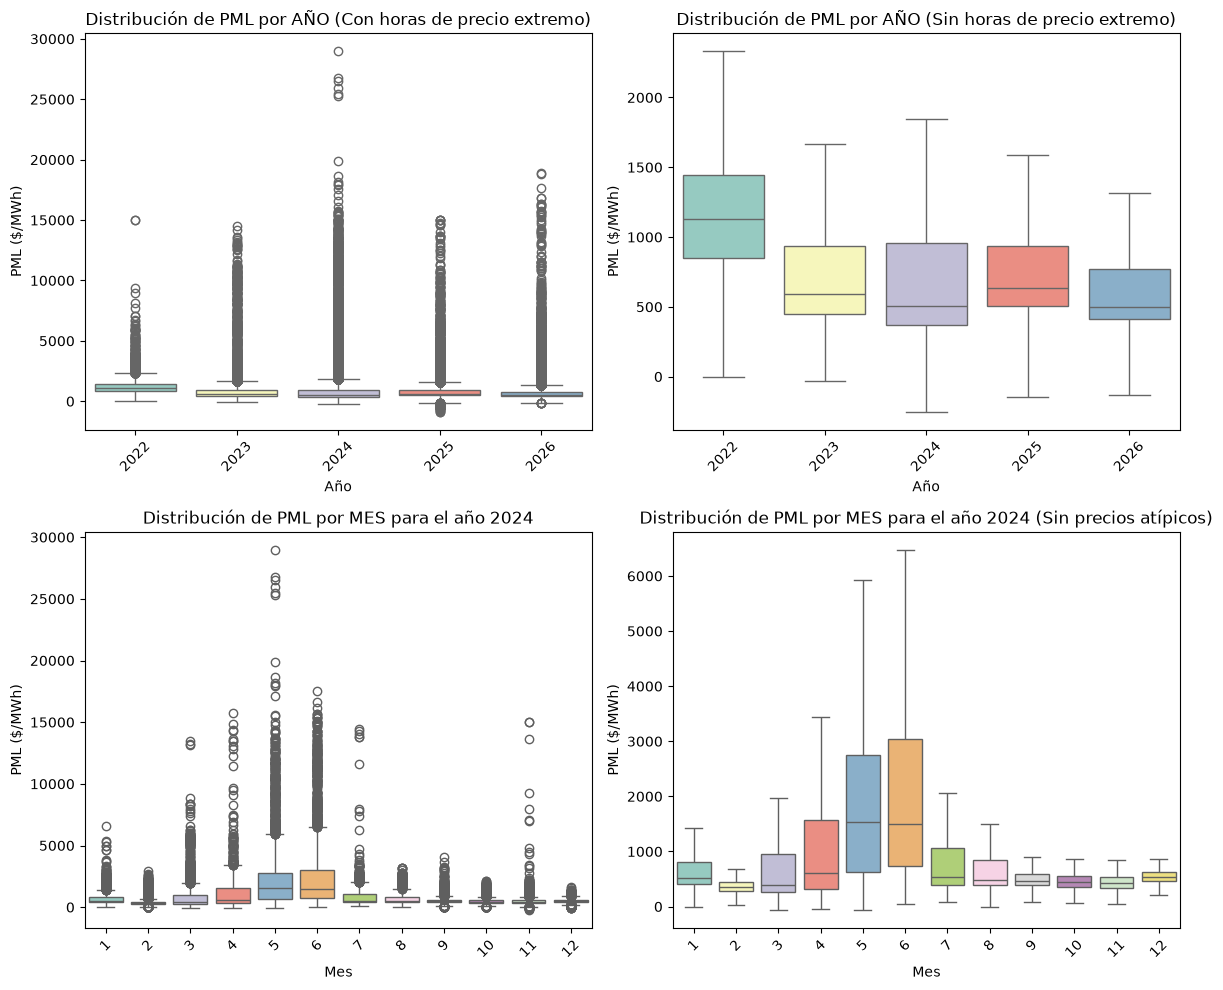

In [183]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

ax1, ax2, ax3, ax4 = axes.flatten()

# --- PANEL 1: Con precios atípicos  ---
sns.boxplot(x='año', hue='año', y='pml', data=df, palette='Set3', legend=False, ax=ax1)
ax1.set_title('Distribución de PML por AÑO (Con horas de precio extremo)')
ax1.set_xlabel('Año')
ax1.set_ylabel('PML ($/MWh)')
ax1.tick_params(axis='x', rotation=45)

# --- PANEL 2: Sin precios atípicos ---
sns.boxplot(x='año', hue='año', y='pml', data=df, palette='Set3', legend=False, showfliers=False, ax=ax2)
ax2.set_title('Distribución de PML por AÑO (Sin horas de precio extremo)')
ax2.set_xlabel('Año')
ax2.set_ylabel('PML ($/MWh)')
ax2.tick_params(axis='x', rotation=45)

# --- Panel 3: Distribución de PML por MES en el año 2024---
sns.boxplot(x='mes', hue='mes', y='pml', data=df[df['año'] == 2024], palette='Set3', legend=False, ax=ax3)
ax3.set_title('Distribución de PML por MES para el año 2024')
ax3.set_xlabel('Mes')
ax3.set_ylabel('PML ($/MWh)')
ax3.tick_params(axis='x', rotation=45)


#---Panel 4: Distribución de PML por MES en el año 2024 (sin precios atípicos)---

sns.boxplot(x='mes', hue='mes', y='pml', data=df[(df['año'] == 2024)], palette='Set3', showfliers=False, legend=False, ax=ax4)
ax4.set_title('Distribución de PML por MES para el año 2024 (Sin precios atípicos)')
ax4.set_xlabel('Mes')
ax4.set_ylabel('PML ($/MWh)')
ax4.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

#### Tabla: promedio, mediana y percentiles por componente y año

In [184]:
cols = ['pml', 'pml_ene', 'pml_per', 'pml_cng']

# Tabla: promedio, mediana y percentiles por componente y año
resumen = (
    df.melt(id_vars='año', value_vars=cols,
            var_name='componente', value_name='valor')
      .groupby(['componente', 'año'])['valor']
      .agg(promedio='mean',
           mediana='median',
           p10=lambda s: s.quantile(0.10),
           p90=lambda s: s.quantile(0.90),
           p99=lambda s: s.quantile(0.99))
      .round(1)
      .reindex(cols, level='componente')
)
display(resumen)

promedio  mediana    p10     p90     p99
componente año                                           
pml        2022    1156.3   1128.1  675.5  1645.6  2419.4
           2023     806.5    593.0  359.3  1466.2  3067.5
           2024     950.3    504.7  260.0  2140.7  7340.8
           2025     872.6    637.3  339.5  1626.9  3700.2
           2026     849.4    498.9  303.1  1883.8  4543.9
pml_ene    2022    1172.4   1137.5  761.5  1591.4  2176.4
           2023     749.2    589.3  391.2  1332.8  2340.4
           2024     894.4    509.4  315.2  1893.7  6737.9
           2025     683.9    589.6  431.6  1100.3  1992.0
           2026     686.6    476.4  376.9  1248.1  3734.9
pml_per    2022      -0.7     11.8 -124.0   101.3   256.1
           2023       7.0     10.0  -89.7    93.8   278.4
           2024      12.3      6.2  -86.6   104.4   464.1
           2025      14.9      4.0 -103.6   128.1   491.5
           2026      10.1     10.6  -81.7    94.2   289.0
pml_cng    2022     -15.4      0.0  -81.0     9.3   616.8
           2023      50.2      0.0  -84.6    86.3  1848.4
           2024      43.7     -0.0 -134.2   111.8  2059.9
           2025     173.8      0.2 -128.3   516.4  2914.4
           2026     152.8      0.0  -98.2   250.4  3575.4

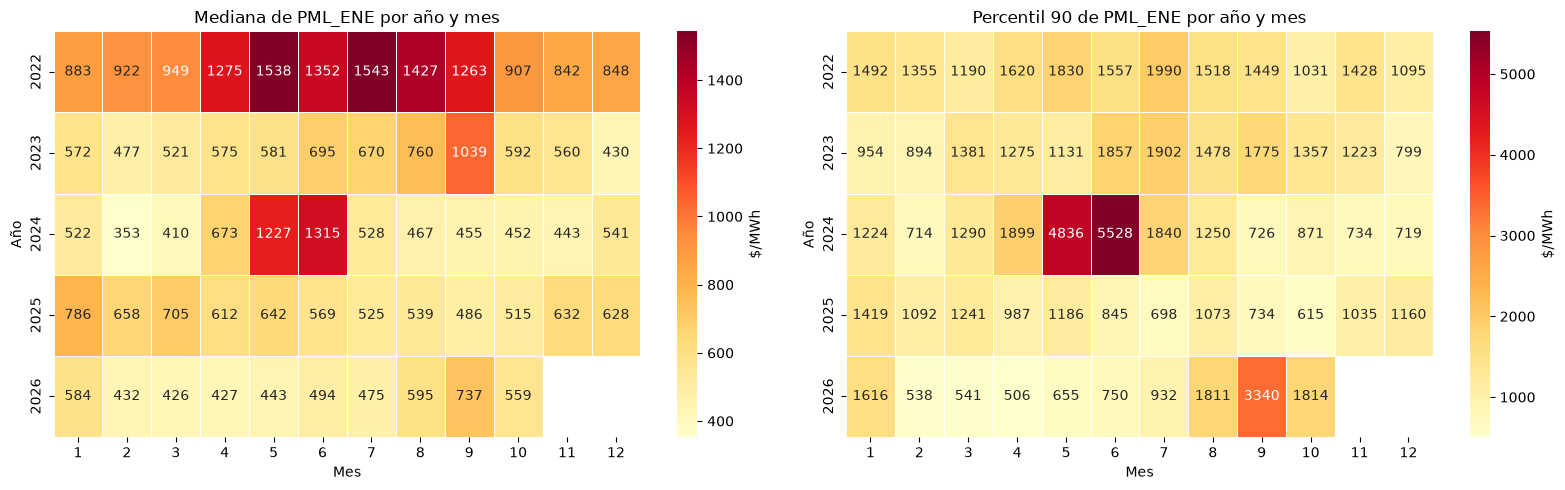

In [185]:
variable = 'pml_ene'   
d = df                 

mediana = d.pivot_table(index='año', columns='mes', values=variable, aggfunc='median')
p90 = d.pivot_table(index='año', columns='mes', values=variable,
                    aggfunc=lambda s: s.quantile(0.90))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, tabla, titulo in zip(axes, [mediana, p90], ['Mediana', 'Percentil 90']):
    sns.heatmap(tabla, annot=True, fmt='.0f', cmap='YlOrRd', linewidths=0.5,
                cbar_kws={'label': '$/MWh'}, ax=ax)
    ax.set_title(f'{titulo} de {variable.upper()} por año y mes')
    ax.set_xlabel('Mes')
    ax.set_ylabel('Año')

plt.tight_layout()
plt.show()

#### Observaciones

**Por año.** Considerando la mediana del componente de energía (PML_ENE), que no se ve afectada por los extremos, 2022 fue el año con precios más altos: 1,137 \$/MWh, entre 1.9 y 2.4 veces las medianas de 2023 a 2026 (589, 509, 590 y 476). No fue un episodio puntual: el mes más barato de 2022 (noviembre, 842 \$/MWh) supera la mediana de 43 de los 46 meses de 2023 a 2026. Como las medianas de pérdidas y congestión de 2022 son cercanas a cero, la diferencia proviene del componente de energía. Esto es consistente con el aumento del costo de los combustibles: el gas natural de referencia (Henry Hub) promedió 6.25 USD/MMBtu en 2022 contra 2.53 en 2023 ([FRED, serie anual](https://fred.stlouisfed.org/series/AHHNGSP)). 

**Episodio de mayo y junio de 2024.** 2024 tiene la cola más pesada: el p99 de PML_ENE es 6,738 \$/MWh, contra 1,992 a 3,735 en los demás años (2,176 en 2022), y su promedio (894) casi duplica su mediana (509). El mapa de calor muestra que esto se concentra en mayo y junio: sus medianas (1,227 y 1,315) son entre 2.7 y 3 veces las de septiembre a noviembre (443 a 455), y su p90 llega a 4,836 y 5,528 \$/MWh, entre 2.6 y 3.5 veces el de esos mismos meses de 2022, año en que las medianas eran incluso más altas. En 2022 se desplazó el nivel de toda la distribución; en 2024 fue un episodio corto con dispersión extrema. Este patrón no se repite como estacionalidad regular en 2023 ni en 2025. Coincide con que 2024 fue el año más caluroso registrado en México ([Forbes/UNAM](https://forbes.com.mx/mexico-vivio-en-2024-el-ano-mas-caluroso-de-su-historia-alertan-expertos-de-la-unam/)) y con que el CENACE declaró Estado Operativo de Alerta el 18 de mayo de 2024 por la ola de calor ([El Financiero](https://www.elfinanciero.com.mx/nacional/2024/05/18/sabado-de-apagones-cenace-declara-estado-de-alerta-en-sistema-electrico-nacional/)). Como el componente de energía es común al sistema, los extremos sugieren escasez general y no un problema local. Falta descartar otros factores (generación hidráulica, indisponibilidad de plantas, suministro de gas) y contrastar con datos de demanda y temperatura.

**Otros episodios.** Septiembre de 2023 (mediana de 1,039 \$/MWh) y agosto a octubre de 2026 (p90 de 1,811, 3,340 y 1,814 \$/MWh) también se apartan del patrón y no se explican con la ola de calor de mayo de 2024; quedan para análisis posterior.


#### Componentes de PML por año

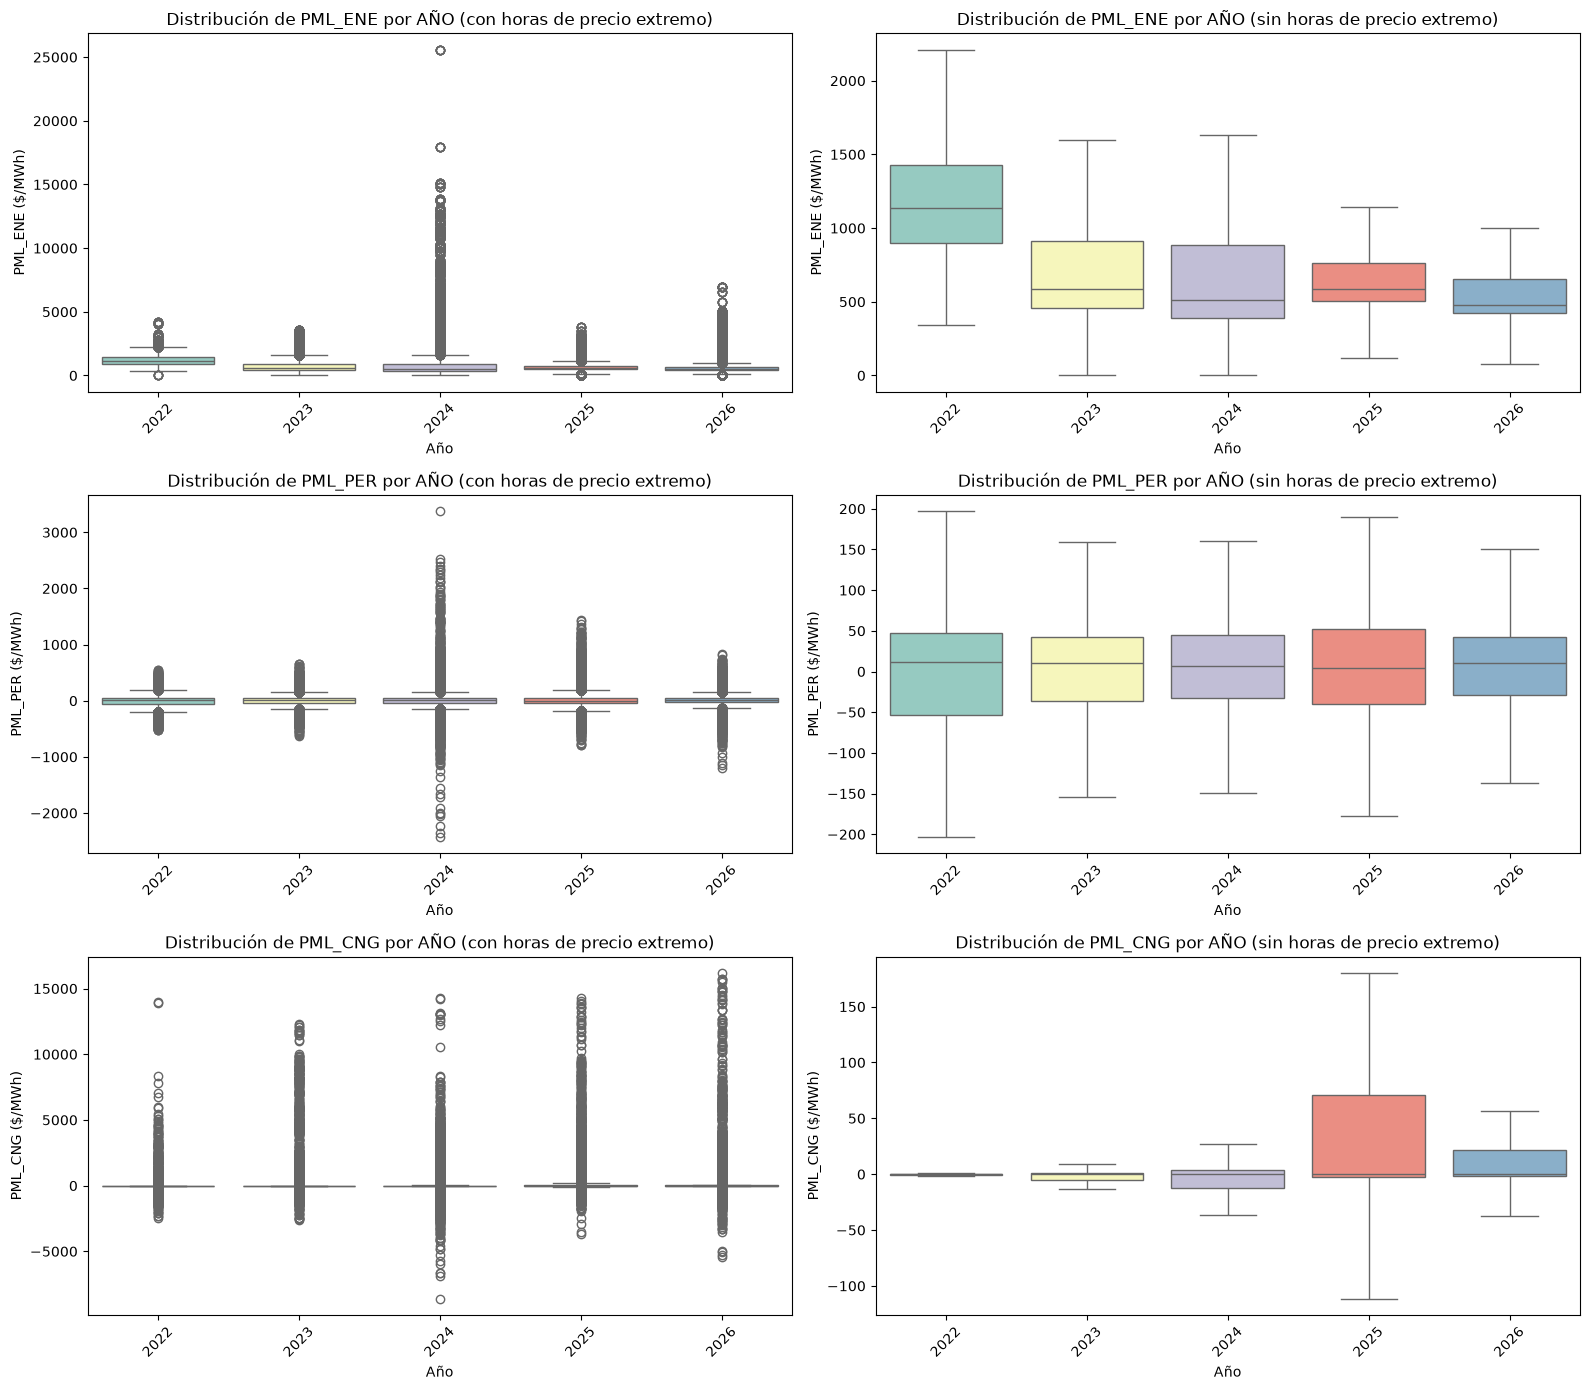

In [186]:

fig, axes = plt.subplots(3, 2, figsize=(16, 14))

ax1, ax2, ax3, ax4, ax5, ax6 = axes.flatten()
# --- PANEL 1: Con precios atípicos ---
sns.boxplot(x='año', hue='año', y='pml_ene', data=df, palette='Set3', legend=False, ax=ax1)
ax1.set_title('Distribución de PML_ENE por AÑO (con horas de precio extremo)')
ax1.set_xlabel('Año')
ax1.set_ylabel('PML_ENE ($/MWh)')
ax1.tick_params(axis='x', rotation=45)
# --- PANEL 2: Sin precios atípicos ---
sns.boxplot(x='año', hue='año', y='pml_ene', data=df, palette='Set3', legend=False, showfliers=False, ax=ax2)
ax2.set_title('Distribución de PML_ENE por AÑO (sin horas de precio extremo)')
ax2.set_xlabel('Año')
ax2.set_ylabel('PML_ENE ($/MWh)')
ax2.tick_params(axis='x', rotation=45)
# --- PANEL 3: Con precios atípicos ---
sns.boxplot(x='año', hue='año', y='pml_per', data=df, palette='Set3', legend=False, ax=ax3)
ax3.set_title('Distribución de PML_PER por AÑO (con horas de precio extremo)')
ax3.set_xlabel('Año')
ax3.set_ylabel('PML_PER ($/MWh)')
ax3.tick_params(axis='x', rotation=45)
# --- PANEL 4: Sin precios atípicos ---
sns.boxplot(x='año', hue='año', y='pml_per', data=df, palette='Set3', legend=False, showfliers=False, ax=ax4)
ax4.set_title('Distribución de PML_PER por AÑO (sin horas de precio extremo)')
ax4.set_xlabel('Año')
ax4.set_ylabel('PML_PER ($/MWh)')
ax4.tick_params(axis='x', rotation=45)
# --- PANEL 5: Con precios atípicos ---
sns.boxplot(x='año', hue='año', y='pml_cng', data=df, palette='Set3', legend=False, ax=ax5)
ax5.set_title('Distribución de PML_CNG por AÑO (con horas de precio extremo)')
ax5.set_xlabel('Año')
ax5.set_ylabel('PML_CNG ($/MWh)')
ax5.tick_params(axis='x', rotation=45)
# --- PANEL 6: Sin precios atípicos ---
sns.boxplot(x='año', hue='año', y='pml_cng', data=df, palette='Set3', legend=False, showfliers=False, ax=ax6)
ax6.set_title('Distribución de PML_CNG por AÑO (sin horas de precio extremo)')
ax6.set_xlabel('Año')
ax6.set_ylabel('PML_CNG ($/MWh)')
ax6.tick_params(axis='x', rotation=45)  


plt.tight_layout()
plt.show()

In [187]:


def mapas_calor(d, variable, q=0.90, sufijo=''):
    """Mediana y percentil q de `variable`, por año y mes."""
    mediana = d.pivot_table(index='año', columns='mes', values=variable, aggfunc='median')
    pq = d.pivot_table(index='año', columns='mes', values=variable,
                       aggfunc=lambda s: s.quantile(q))

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    for ax, tabla, titulo, fmt in zip(axes, [mediana, pq],
                                      ['Mediana', f'Percentil {int(q*100)}'],
                                      ['.1f', '.0f']):
        sns.heatmap(tabla, annot=True, fmt=fmt, cmap='RdBu_r', center=0,
                    linewidths=0.5, cbar_kws={'label': '$/MWh'}, ax=ax)
        ax.set_title(f'{titulo} de {variable.upper()} por año y mes{sufijo}')
        ax.set_xlabel('Mes')
        ax.set_ylabel('Año')
    plt.tight_layout()
    plt.show()



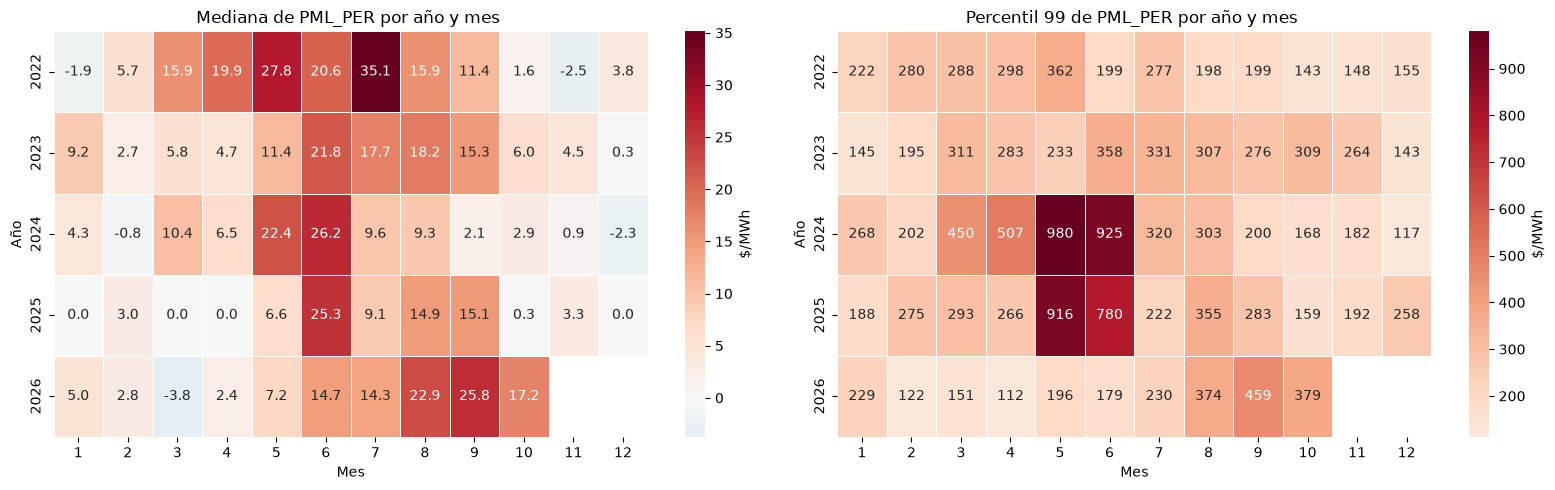

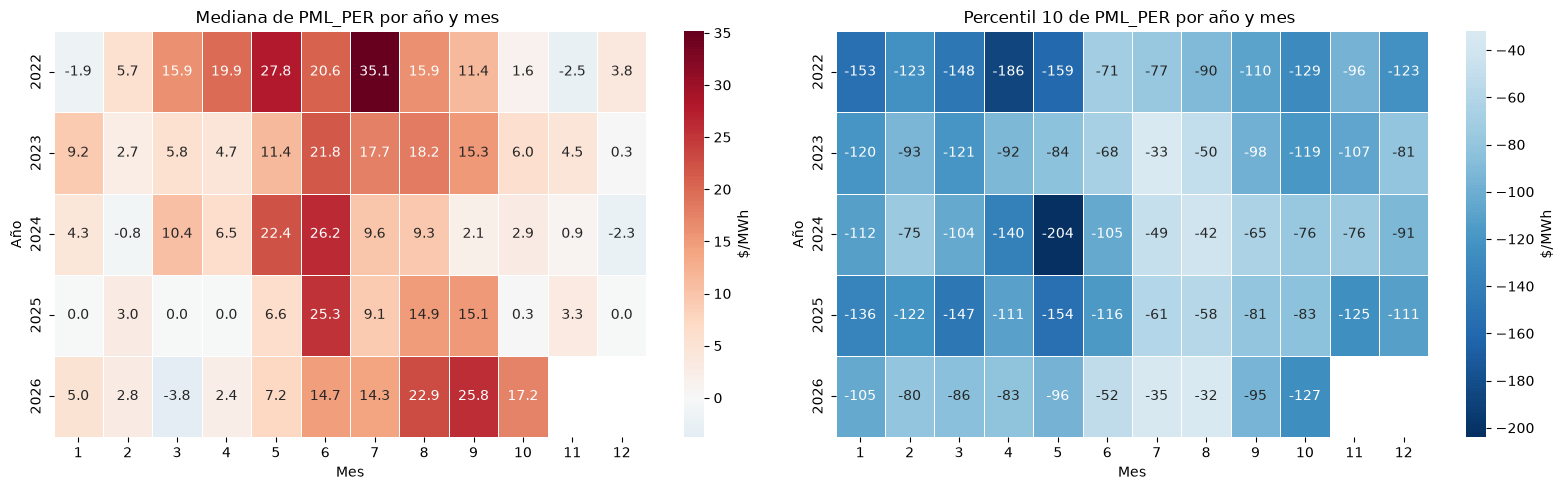

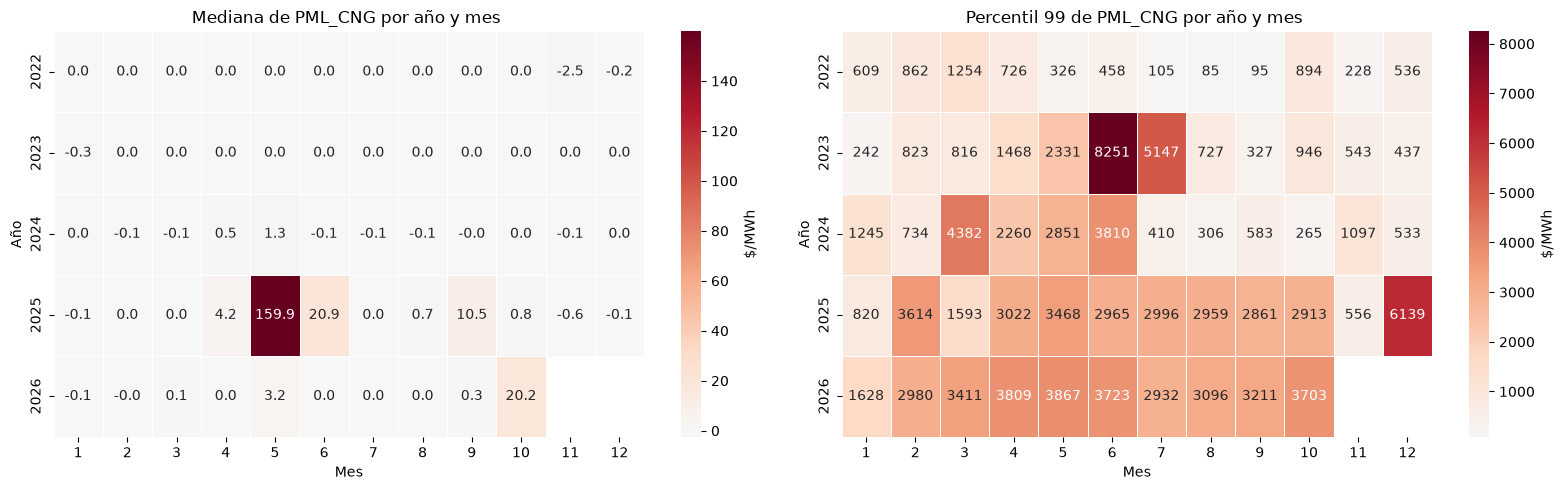

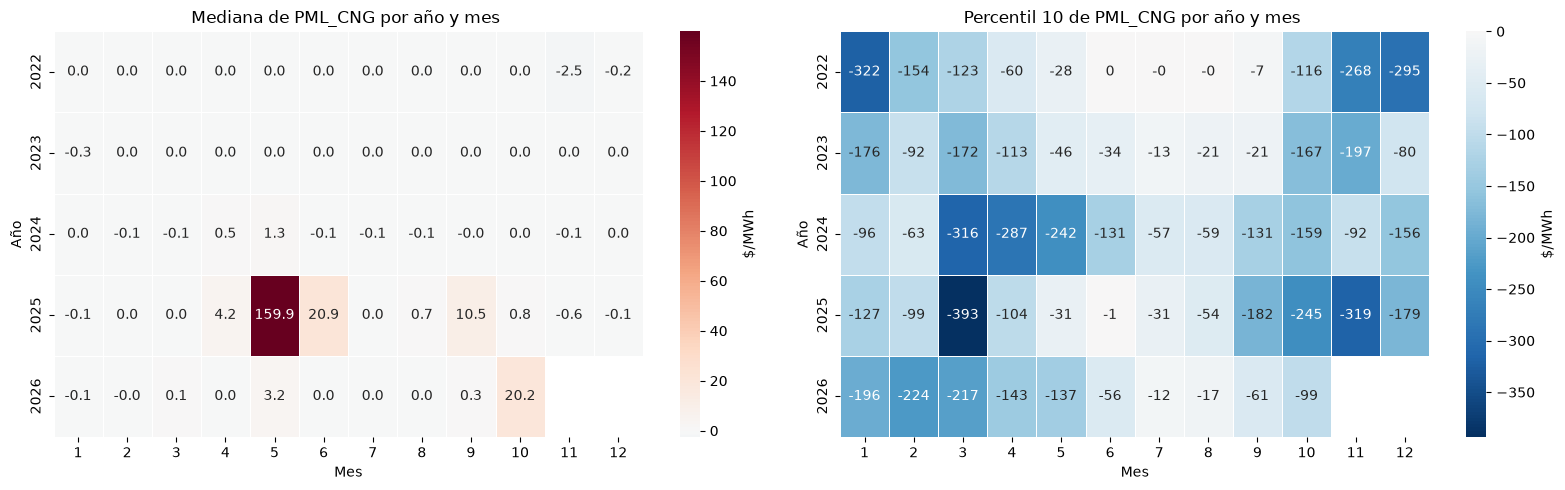

In [188]:
# Un nodo con valores positivos y otro con negativos
for variable in ['pml_per', 'pml_cng']:
    mapas_calor(df, variable, q=0.99,sufijo=' ')
    mapas_calor(df, variable, q=0.10, sufijo=' ')

### Observaciones

Los resultados de esta sección agrupan los 6 nodos analizados, que se eligieron para cubrir zonas distintas (no son una muestra aleatoria), por lo que no pueden generalizarse a toda la red. Como pérdidas y congestión dependen del nodo, el siguiente paso es repetirlos por nodo.

**Componente de energía.** Es el principal componente del PML: en promedio explica el 93% del PML en 2022–2024 y baja a 78% y 81% en 2025 y 2026, porque aumenta la congestión.

**Pérdidas.** Las medianas anuales son similares (entre 4.0 y 11.8 \$/MWh, de 0.7% a 2.2% de la mediana del componente de energía). Por mes hay una estacionalidad que se repite cada año: las medianas más altas ocurren entre mayo y septiembre (hasta 35.1 \$/MWh en julio de 2022 y 27.8 en mayo de 2022) y las más bajas en invierno (de −3.8 a 5), lo cual es consistente con una mayor carga de la red en los meses calurosos. Los valores extremos (p99) llegan a 780–980 \$/MWh en mayo y junio de 2024 y 2025. Como el componente de pérdidas es proporcional al precio de la energía, 2022 parece el año con más pérdidas en pesos.

**Congestión.** La mediana mensual es cercana a 0 \$/MWh en casi todos los meses: la mayoría de las horas no hay congestión. Lo que cambia es la cola. De 2022 a 2024, el p99 superó 2,800 \$/MWh en [5] de 36 meses (episodios como junio y julio de 2023 y marzo a junio de 2024); de febrero de 2025 a octubre de 2026 lo hizo en [18] de 21 meses, es decir, la congestión pasó de episodios aislados a un fenómeno persistente. En mayo de 2025, la mediana mensual llegó a 159.9 \$/MWh, lo que implica congestión en más de la mitad de las observaciones [pendiente de verificar por nodo]. Una posible explicación es la saturación de la red por la demanda industrial ([Milenio](https://www.milenio.com/negocios/ven-saturacion-electrica-alta-demanda-industrial-mexico)).

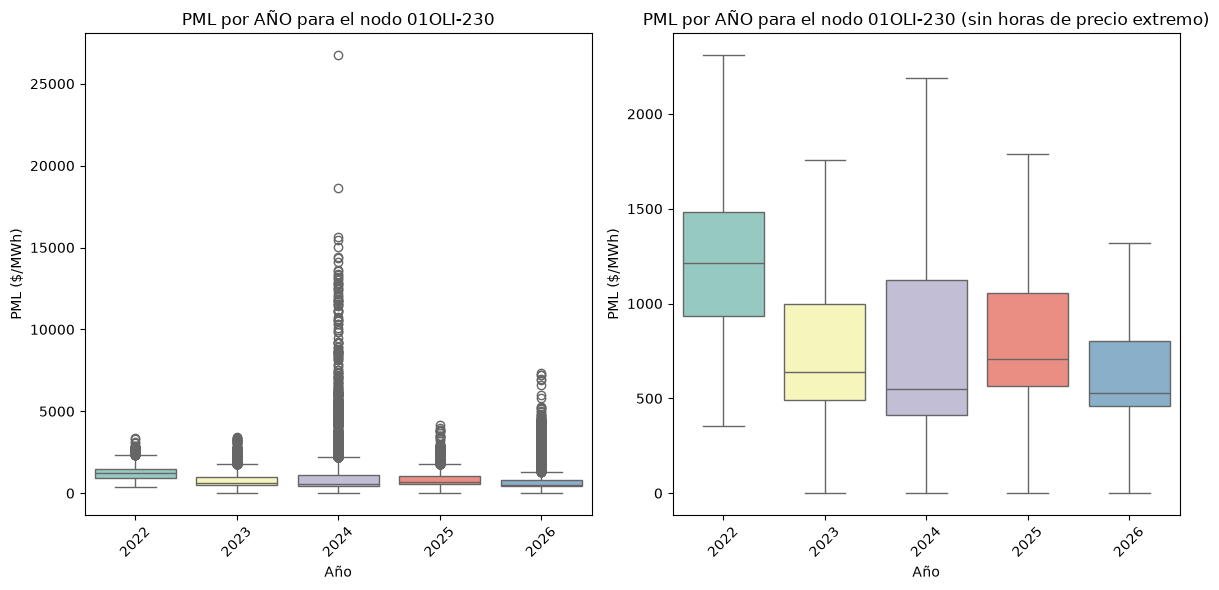

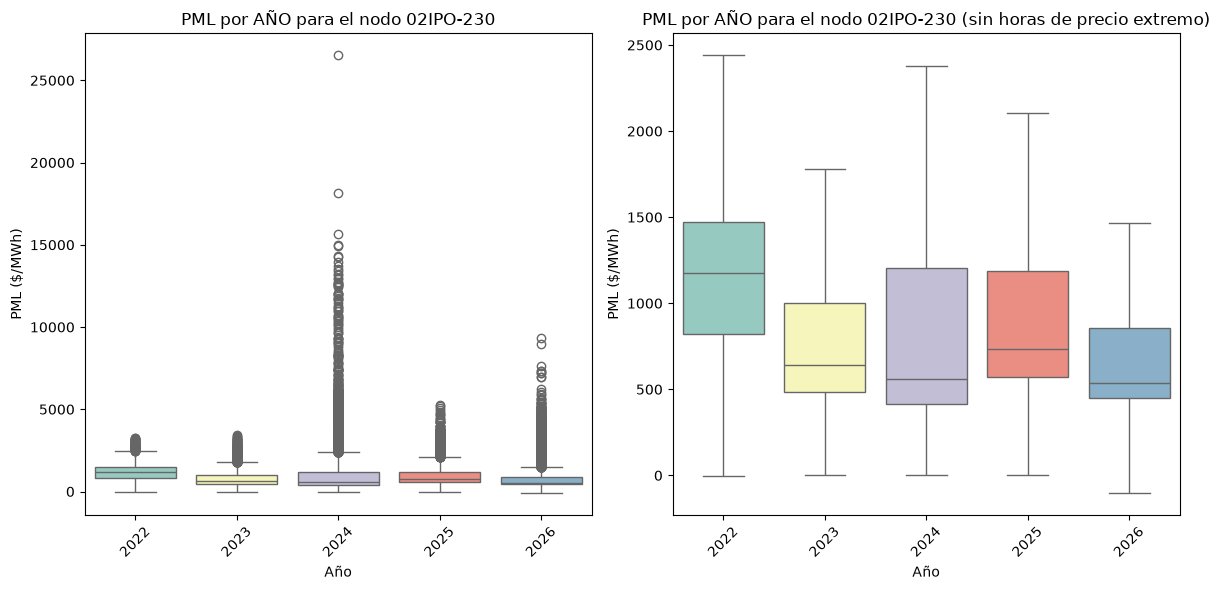

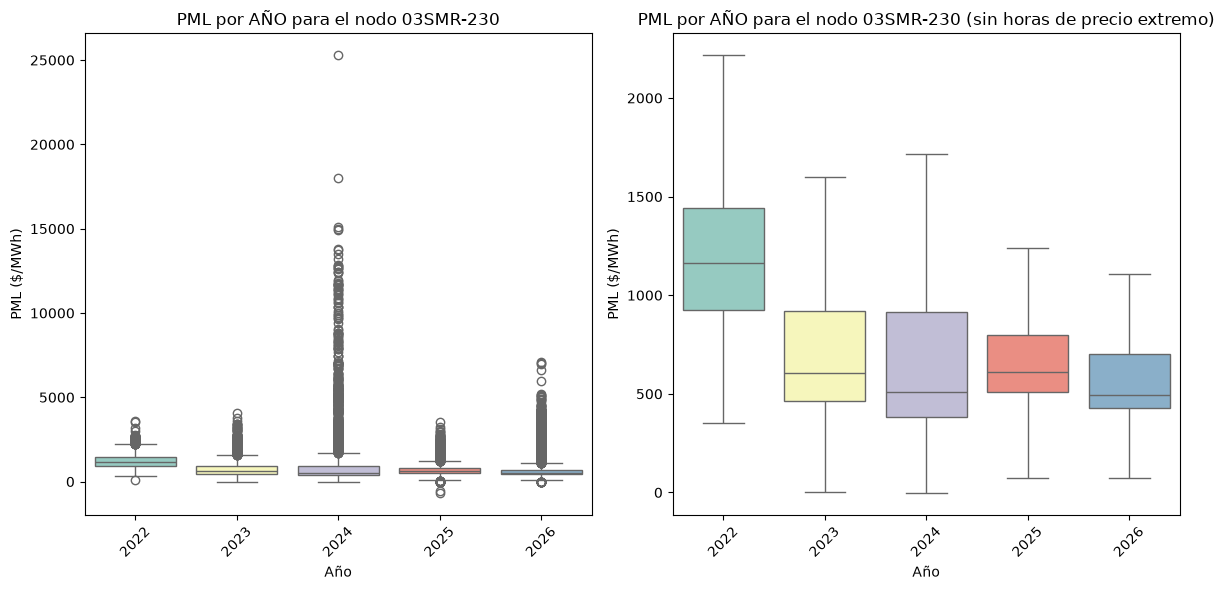

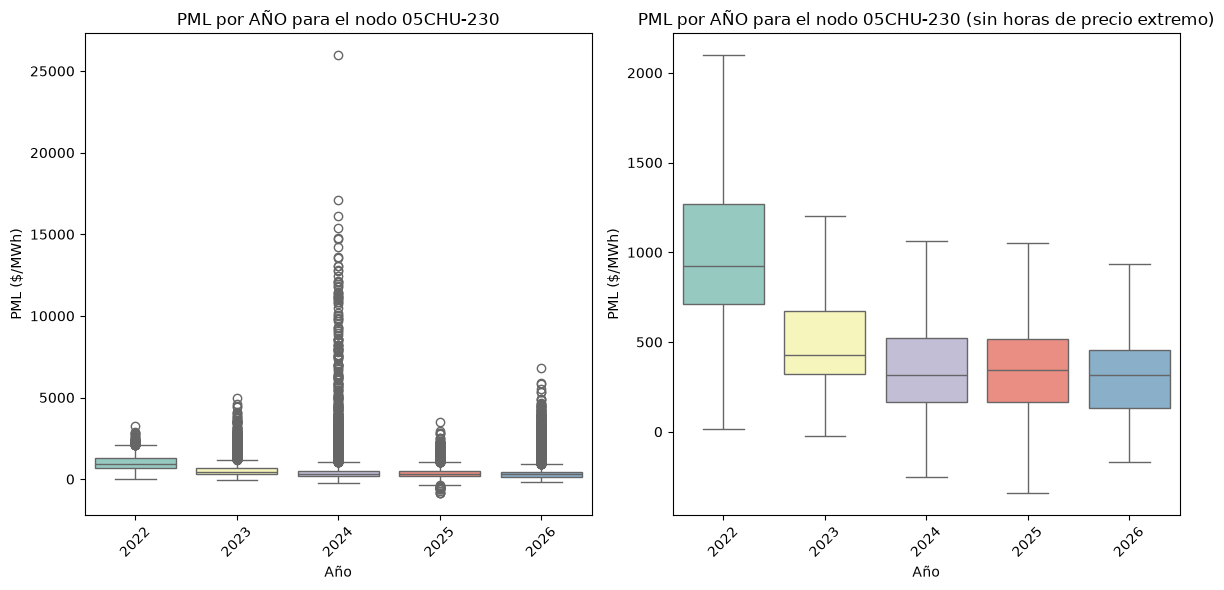

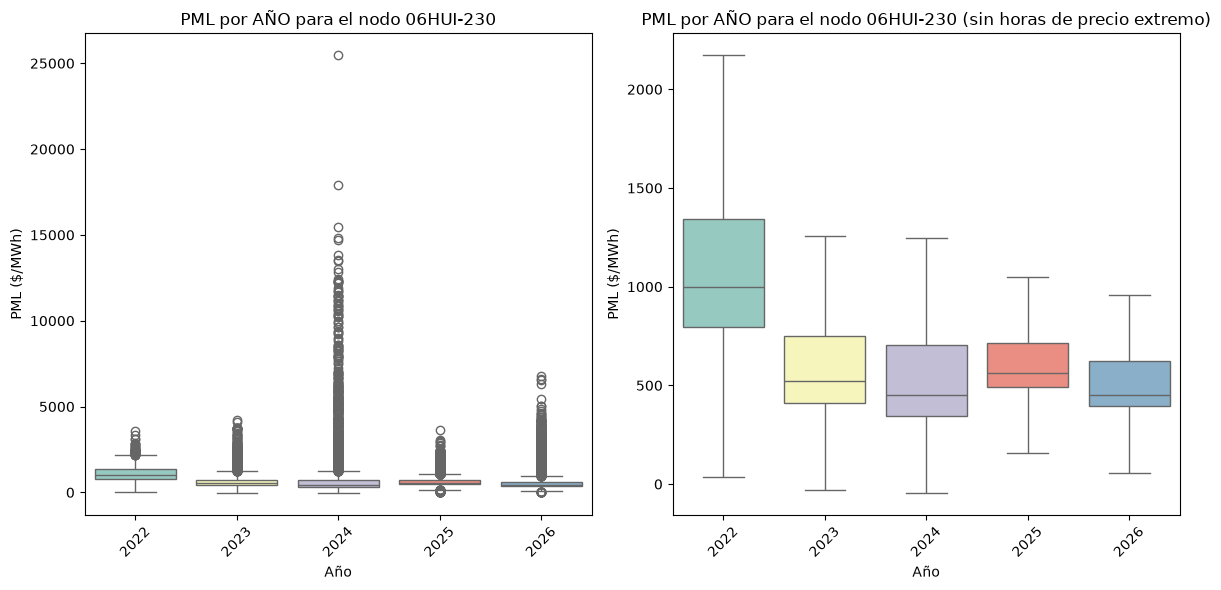

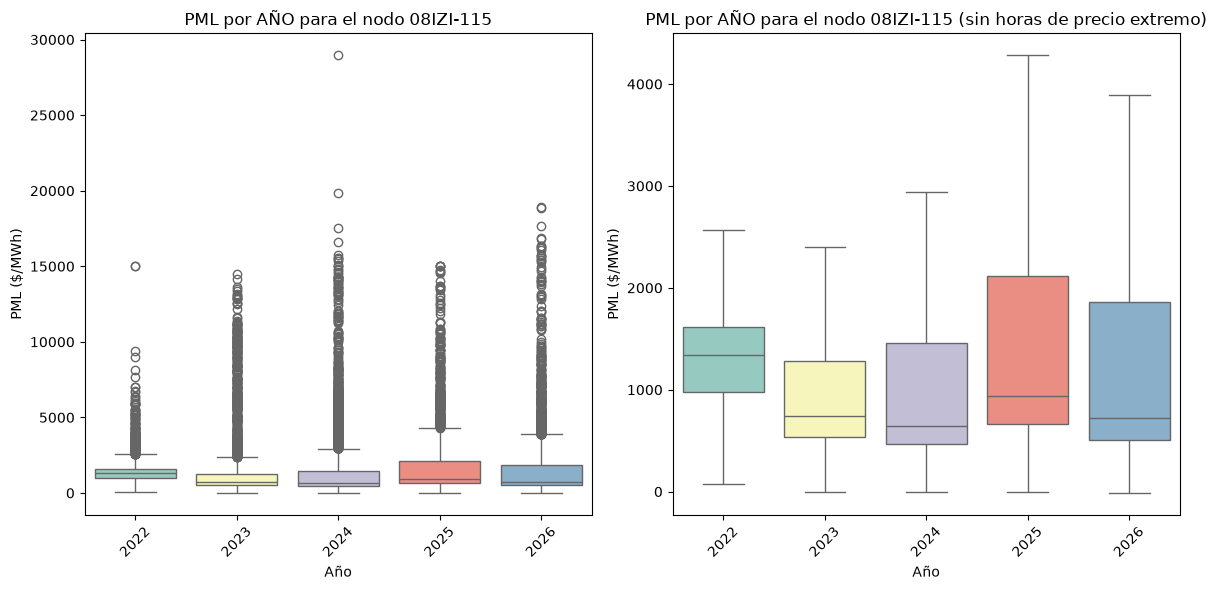

In [189]:
# nodo por año
for nodo in df['nodo'].unique():
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
    sns.boxplot(x='año', hue='año', y='pml', data=df[df['nodo'] == nodo], palette='Set3', legend=False, ax=ax1)
    ax1.set_title(f'PML por AÑO para el nodo {nodo}')
    ax1.set_xlabel('Año')
    ax1.set_ylabel('PML ($/MWh)')
    ax1.tick_params(axis='x', rotation=45)
    sns.boxplot(x='año', hue='año', y='pml', data=df[df['nodo'] == nodo], palette='Set3', legend=False, showfliers=False, ax=ax2)
    ax2.set_title(f'PML por AÑO para el nodo {nodo} (sin horas de precio extremo)')
    ax2.set_xlabel('Año')
    ax2.set_ylabel('PML ($/MWh)')
    ax2.tick_params(axis='x', rotation=45)
    plt.tight_layout()
    plt.show()

### Tabla porcentaje de horas con congestión > 100 \$\/MWh, p10 y p99 de congestión 

### Tablas porcentaje de horas de congestion positiva y negativa de los Meses Enero a Octubre 

In [191]:
UMBRAL = 100
base = df[df['mes'] <= 10]   # 2026 llega hasta octubre

pos = ((base['pml_cng'] >  UMBRAL).groupby([base['nodo'], base['año']]).mean().mul(100).round(1).unstack('año'))
neg = ((base['pml_cng'] < -UMBRAL).groupby([base['nodo'], base['año']]).mean().mul(100).round(1).unstack('año'))
display(pos); display(neg)


p99_cong = (
    base.groupby(['nodo', 'año'])['pml_cng'].quantile(0.99)
    .round(0).unstack('año')
)
p10_cong = (
    base.groupby(['nodo', 'año'])['pml_cng'].quantile(0.10)
    .round(0).unstack('año')
)

display(p99_cong)    # p99 de la congestión, por nodo y año
display(p10_cong)    # p10 de la congestión, por nodo y año

año,2022,2023,2024,2025,2026
nodo,,,,,
01OLI-230,6.1,8.8,13.7,27.9,18.5
02IPO-230,7.0,10.5,17.6,34.2,23.7
03SMR-230,0.9,3.8,5.2,13.7,7.5
05CHU-230,0.8,6.2,3.4,6.0,1.2
06HUI-230,0.8,7.0,4.0,17.0,4.8
08IZI-115,12.3,24.0,24.2,47.3,41.0


año,2022,2023,2024,2025,2026
nodo,,,,,
01OLI-230,1.2,1.4,0.7,0.3,0.0
02IPO-230,10.1,3.4,3.0,0.7,1.7
03SMR-230,0.9,2.5,3.9,2.4,0.3
05CHU-230,16.9,26.9,51.8,51.9,53.7
06HUI-230,10.4,13.6,13.5,3.3,3.1
08IZI-115,1.5,1.9,0.9,0.4,0.5


año,2022,2023,2024,2025,2026
nodo,,,,,
01OLI-230,394.0,689.0,1093.0,1678.0,1546.0
02IPO-230,639.0,869.0,2837.0,2824.0,3036.0
03SMR-230,95.0,298.0,197.0,460.0,323.0
05CHU-230,83.0,739.0,444.0,281.0,114.0
06HUI-230,90.0,666.0,331.0,463.0,210.0
08IZI-115,2171.0,8212.0,4170.0,5373.0,7372.0


año,2022,2023,2024,2025,2026
nodo,,,,,
01OLI-230,-0.0,-7.0,-0.0,-0.0,-0.0
02IPO-230,-115.0,-16.0,-2.0,-0.0,-0.0
03SMR-230,-11.0,-21.0,-32.0,-24.0,-4.0
05CHU-230,-183.0,-280.0,-506.0,-414.0,-303.0
06HUI-230,-106.0,-158.0,-161.0,-22.0,-21.0
08IZI-115,-0.0,-6.0,-1.0,-0.0,-0.0


### Observaciones

*Porcentajes calculados sobre enero–octubre de cada año para poder comparar con 2026. Umbral de congestión: |PML_CNG| > 100 MXN/MWh (elegido de forma arbitraria).*

**Auge en 2025.** El porcentaje de horas con congestión positiva (> 100 MXN/MWh) alcanzó su máximo en 2025 en cinco de los seis nodos. Respecto a 2024 se multiplicó por 1.8–2.6 en CHU, IPO, IZI, OLI y SMR, y por 4.25 en 06HUI-230 (de 4.0% a 17.0%, +13 puntos). En 2026 el porcentaje baja en los seis nodos.

**08IZI-115 (Mérida).** Es el nodo con congestión positiva más frecuente y más extrema: pasó de 12.3% de las horas en 2022 a 47.3% en 2025 y 41.0% en 2026 (casi se cuadruplicó). Su p99 es el más alto de los seis nodos en todos los años: 1,968 MXN/MWh en 2022 y entre 4,013 y 7,853 MXN/MWh de 2023 a 2026. La congestión negativa casi no aparece (≤ 1.9% de las horas). 


**08IZI-115, estacionalidad.** La mediana mensual de PML_CNG es ≈ 0 en la mayoría de los meses, pero el p90 supera 1,500 MXN/MWh en muchos de ellos, lo que indica una congestión concentrada en una fracción de las horas. En 2023 y 2024 el p90 elevado se concentra en marzo–julio (máximo de 6,887 MXN/MWh en junio de 2023); desde 2025 se extiende a casi todo el año (p90 entre 2,300 y 3,300 MXN/MWh en 9 de 12 meses) y continúa en 2026. Mayo de 2025 destaca por una mediana de 1,569 MXN/MWh

**05CHU-230 (Chihuahua).** Es el único nodo con congestión predominantemente negativa: pasó de 16.9% de las horas con CNG < −100 MXN/MWh en 2022 a 51.8% en 2024, 51.9% en 2025 y 53.7% en 2026, mientras que la positiva nunca supera 6.2%. Su p10 estuvo entre −303 y −450 MXN/MWh desde 2024 (−256 en 2022).

**02IPO-230 (Istmo).** Cambió de signo: la congestión negativa bajó de 10.1% (2022) a 0.7% (2025), mientras que la positiva subió de 7.0% a 34.2%. 

### Congestión del nodo 08IZI-115, ¿Existen efectos de estacionalidad (hora y mes) y balance energético?

In [192]:
# 1) Cargar la demanda (la que genera demanda_merge.py)
dem = pd.read_csv('https://raw.githubusercontent.com/German-rl/Precios_Marginales_MDA/refs/heads/main/CENACE_PML/data/demanda_balance.csv', parse_dates=['timestamp'])
pen = dem[(dem['sistema'] == 'SIN') & (dem['area'].str.contains('Pen', case=False))]   # ajusta al nombre real

iz = df[(df['nodo'] == '08IZI-115') & (df['hora'] <= 24)].merge(
    pen[['timestamp', 'demanda_mwh']], on='timestamp', how='left')
print(iz['demanda_mwh'].isna().mean())
iz.head(15)


0.0


,timestamp,hora,pml,pml_ene,pml_per,pml_cng,nodo,mes,año,dia,fin_semana,dia_semana,fecha,demanda_mwh
0,2022-01-01 00:00:00,1,719.29,636.84,82.45,0.00,08IZI-115,1,2022,1,True,5,2022-01-01,1350.48659
1,2022-01-01 01:00:00,2,695.27,612.33,82.94,0.00,08IZI-115,1,2022,1,True,5,2022-01-01,1338.70471
2,2022-01-01 02:00:00,3,691.81,605.54,86.27,0.00,08IZI-115,1,2022,1,True,5,2022-01-01,1327.99681
3,2022-01-01 03:00:00,4,678.34,594.32,84.02,0.00,08IZI-115,1,2022,1,True,5,2022-01-01,1312.16839
4,2022-01-01 04:00:00,5,656.22,571.95,84.27,0.00,08IZI-115,1,2022,1,True,5,2022-01-01,1297.58361
5,2022-01-01 05:00:00,6,650.27,566.29,83.98,0.00,08IZI-115,1,2022,1,True,5,2022-01-01,1279.35931
6,2022-01-01 06:00:00,7,624.77,553.39,71.39,0.00,08IZI-115,1,2022,1,True,5,2022-01-01,1234.22424
7,2022-01-01 07:00:00,8,610.93,540.06,70.87,0.00,08IZI-115,1,2022,1,True,5,2022-01-01,1212.11165
8,2022-01-01 08:00:00,9,544.38,473.74,70.64,0.00,08IZI-115,1,2022,1,True,5,2022-01-01,1241.42446
9,2022-01-01 09:00:00,10,494.70,413.03,81.68,0.00,08IZI-115,1,2022,1,True,5,2022-01-01,1273.87197


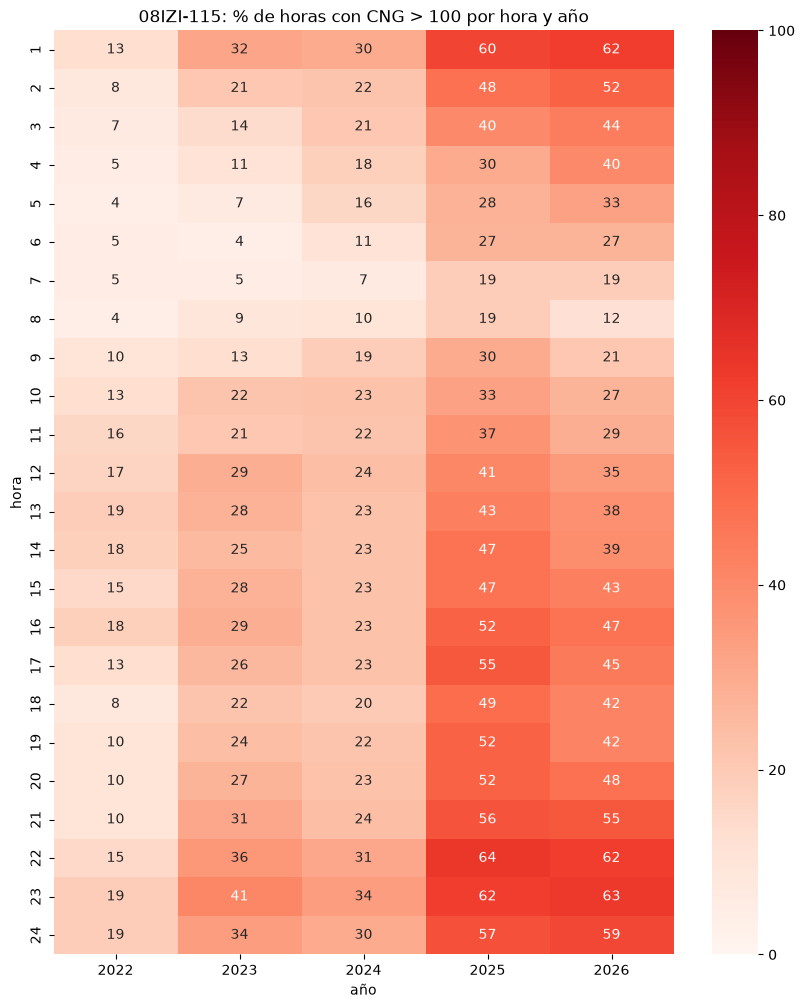

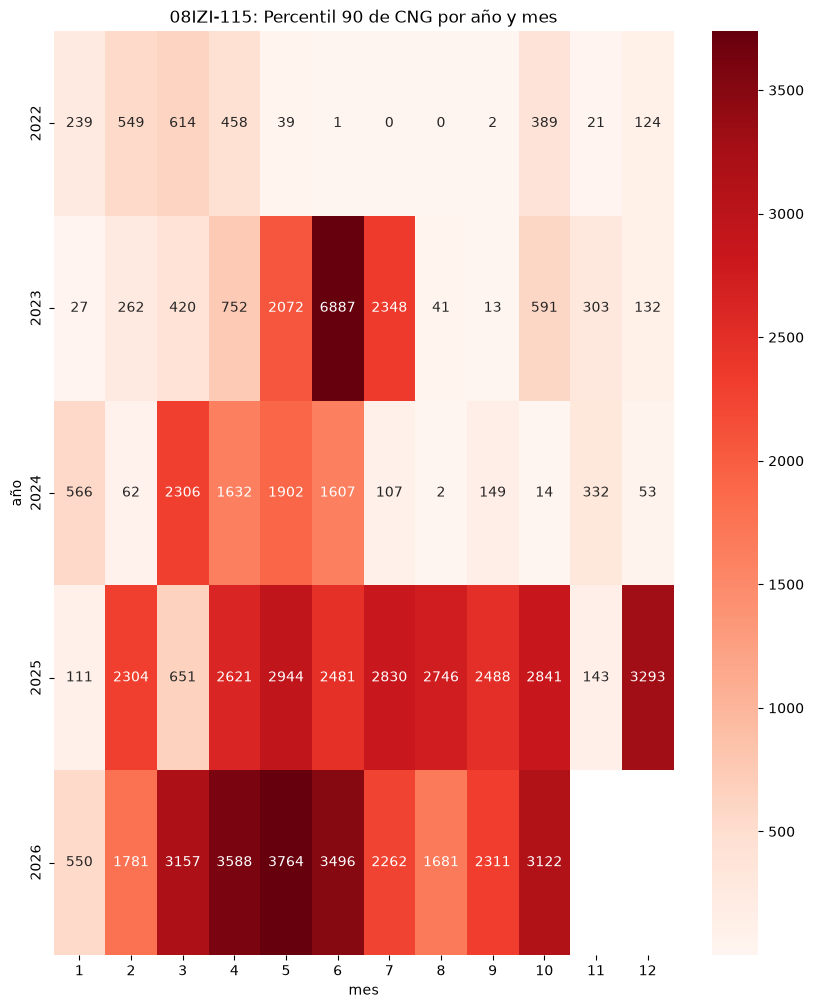

In [193]:

# 2) ¿A qué horas? % de horas con CNG > 100, por hora y año
iz24 = iz[iz['hora'] <= 24]
tab = ((iz24['pml_cng'] > 100).groupby([iz24['hora'], iz24['año']]).mean().mul(100).round(0).unstack('año'))
plt.figure(figsize=(10, 12))
sns.heatmap(tab, annot=True, fmt='.0f', cmap='Reds', vmin=0, vmax=100)
plt.title('08IZI-115: % de horas con CNG > 100 por hora y año'); plt.show()

# 3) Mapa por mes sin que dos valores extremos apaguen el resto
fig, ax = plt.subplots(figsize=(10, 12))
sns.heatmap(iz.pivot_table(index='año', columns='mes', values='pml_cng', aggfunc=lambda s: s.quantile(0.9)),
            annot=True, fmt='.0f', cmap='Reds', robust=True)
plt.title('08IZI-115: Percentil 90 de CNG por año y mes'); plt.show()

In [194]:
from pathlib import Path
from generacion_prep import preparar_generacion

data = Path('..') / 'CENACE_PML' / 'data'
    

csv  = next(data.glob('Generaci*.csv'))
xlsx = next(data.glob('Cat*NodosP*.xlsx'))
print(csv.name, xlsx.name, sep='\n')

gen, total = preparar_generacion(csv, xlsx)

Generación bruta de energía eléctrica por entidad federativa-2026_11_25-12_24_05-pm.csv
Catálogo NodosP Sistema Eléctrico Nacional (v2026-10-23).xlsx
1,624 filas; 2022-01 a 2026-08
Sin zona: ['Plantas Móviles']
Estados repartidos en varias zonas (se usó la dominante):
         estado       zona  zona_pct_nodos
       Coahuila    NORESTE            60.0
       Guerrero   ORIENTAL            89.0
        Hidalgo    CENTRAL            73.0
      Michoacán OCCIDENTAL            81.0
        Morelos   ORIENTAL            96.0
         Puebla   ORIENTAL            94.0
San Luis Potosí OCCIDENTAL            89.0
         Sonora   NOROESTE            95.0
       Veracruz   ORIENTAL            96.0
Máxima diferencia entre la suma de estados y la fila Total: 0.0 MWh


In [195]:
pen_gen = gen[gen['zona'] == 'PENINSULAR'].groupby('fecha')['generacion_mwh'].sum()

# demanda mensual de la Península (del archivo que armó demanda_merge.py)
dem = pd.read_csv('https://raw.githubusercontent.com/German-rl/Precios_Marginales_MDA/refs/heads/main/CENACE_PML/data/demanda_balance.csv', parse_dates=['timestamp'])
print(dem['area'].unique())     # mira cómo se llama exactamente el área peninsular
pen_dem = (dem[dem['area'].str.contains('PEN', case=False)]
           .set_index('timestamp')['demanda_mwh'].resample('MS').sum())

imp = (pen_dem - pen_gen).dropna()      # MWh por mes; > 0: la región importa (aproximado)
imp.name = 'import_mwh'
print(imp.head())

<StringArray>
['BCA', 'CEN', 'NES', 'NOR', 'NTE', 'OCC', 'ORI', 'PEN']
Length: 8, dtype: str
timestamp
2022-01-01    489964.03246
2022-02-01    535550.98655
2022-03-01    679515.29589
2022-04-01    554327.01373
2022-05-01    545096.00022
Name: import_mwh, dtype: float64


In [196]:
iz24 = iz[iz['hora'] <= 24].copy()
iz24 = iz24.set_index('timestamp').sort_index()
iz24['cong'] = iz24['pml_cng'] > 100
pct = iz24['cong'].resample('MS').mean().mul(100)
m = (iz24.resample('MS')
         .agg(dem_media=('demanda_mwh', 'mean'),
              dem_p90=('demanda_mwh', lambda s: s.quantile(0.9)),
              pct_cong=('cong', lambda s: s.mean() * 100),
              cng_mediana=('pml_cng', 'median'),
              cng_p90=('pml_cng', lambda s: s.quantile(0.9))))

# generación e importación en MW promedio (MWh del mes / horas del mes),
# para que estén en las mismas unidades que la demanda horaria
horas = lambda idx: idx.days_in_month.to_numpy() * 24
gen_mw = pen_gen / horas(pen_gen.index)
imp_mw = imp / horas(imp.index)



In [197]:
def grafico_nodo(df, dem, gen, nodo, area_dem, estados_gen, signo=+1, umbral=100, exacto=False):
    if exacto:
        d = dem[dem['area'].str.strip().str.upper() == area_dem.upper()]
    else:
        d = dem[dem['area'].str.contains(area_dem, case=False)]
    if d.empty:
        raise ValueError(f"Ninguna área coincide con '{area_dem}'. Disponibles: {sorted(dem['area'].unique())}")
    print('Áreas de demanda usadas:', d['area'].unique())
             # verifica que sea la región correcta
    d = d.groupby('timestamp')['demanda_mwh'].sum().rename('demanda_mwh').reset_index()

    x = df[(df['nodo'] == nodo) & (df['hora'] <= 24)].merge(d, on='timestamp')
    x['cong'] = (x['pml_cng'] * signo) > umbral
    cola = 0.9 if signo > 0 else 0.1                                # p90 si es positiva, p10 si es negativa
    m = (x.set_index('timestamp').resample('MS')
           .agg(dem_media=('demanda_mwh', 'mean'),
                pct_cong=('cong', lambda s: s.mean() * 100),
                cng_cola=('pml_cng', lambda s: s.quantile(cola)),
                cng_mediana=('pml_cng', 'median')))

    horas = lambda idx: idx.days_in_month.to_numpy() * 24
    gen_mw = {}
    for nombre, lista in estados_gen.items():
        g = gen[gen['estado'].isin(lista)].groupby('fecha')['generacion_mwh'].sum()
        gen_mw[nombre] = g / horas(g.index)                         # MWh del mes -> MW promedio

    fig, ax = plt.subplots(4, 1, figsize=(14, 12), sharex=True)
    ax[0].plot(m.index, m['dem_media'], label='demanda media (región)', color='tab:blue')
    for (nombre, g), c in zip(gen_mw.items(), ['tab:green', 'tab:olive']):
        ax[0].plot(g.index, g, color=c, label=f'generación media: {nombre}')
    ax[0].set_ylabel('MW'); ax[0].legend(loc='upper left', ncol=2)

    for (nombre, g), c in zip(gen_mw.items(), ['tab:brown', 'tab:orange']):
        bal = (m['dem_media'] - g).dropna()
        ax[1].plot(bal.index, bal, color=c, label=nombre)
    ax[1].axhline(0, color='k', lw=.8); ax[1].legend(loc='upper left')
    ax[1].set_ylabel('Demanda − generación\n(MW prom.; >0 importa, <0 exporta)')

    ax[2].plot(m.index, m['pct_cong'], color='tab:red')
    ax[2].set_ylabel(f"% horas con CNG {'>' if signo > 0 else '< -'}{umbral}")

    ax[3].plot(m.index, m['cng_cola'], color='tab:purple', label=f'p{int(cola*100)}')
    ax[3].plot(m.index, m['cng_mediana'], color='tab:gray', label='mediana')
    ax[3].axhline(0, color='k', lw=.8)
    ax[3].set_ylabel('PML_CNG (MXN/MWh)'); ax[3].legend()

    for a in ax:
        for y in range(2022, 2027):
            a.axvspan(pd.Timestamp(f'{y}-05-01'), pd.Timestamp(f'{y}-06-30'), color='orange', alpha=.12)
    fig.suptitle(f'{nodo}: demanda, generación, balance y congestión (mensual)', y=0.995)
    plt.tight_layout(); plt.show()
    return m






### Balance energético, ¿Existen un efectos en la congestión de 08IZI-115?

Áreas de demanda usadas: <StringArray>
['PEN']
Length: 1, dtype: str


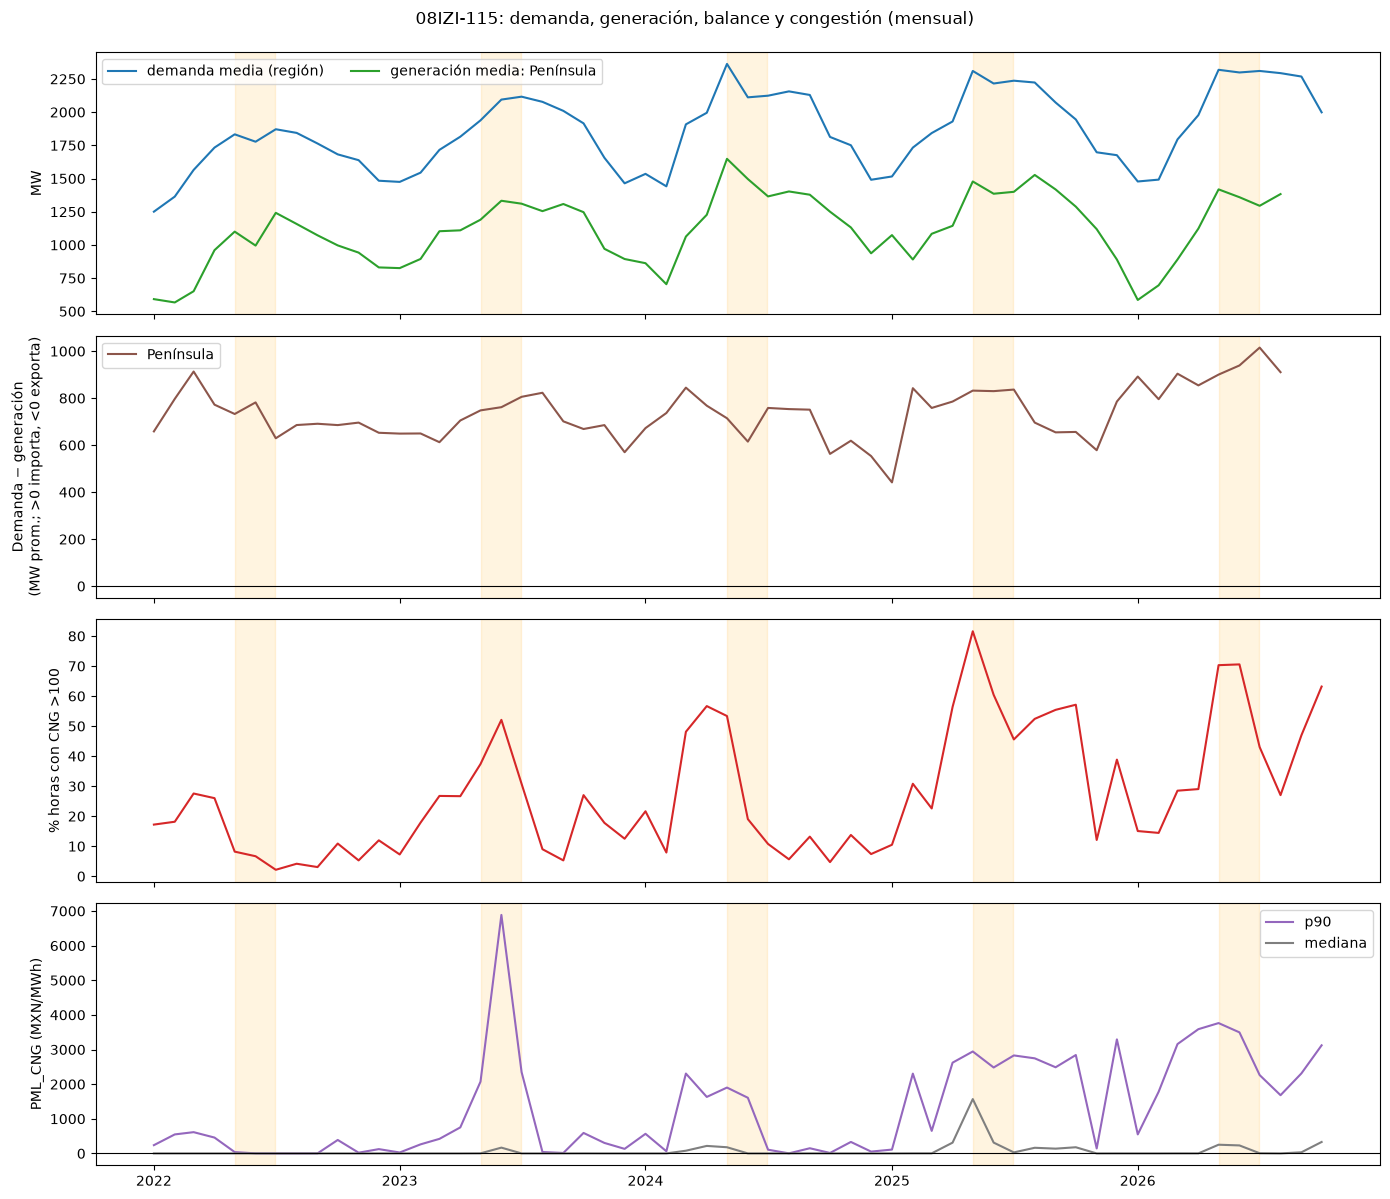

In [198]:
m_izi = grafico_nodo(df, dem, gen, '08IZI-115', area_dem='pen', signo=+1,
                     estados_gen={'Península': ['Campeche', 'Quintana Roo', 'Yucatán']})

            import_mwh  pct_cong
import_mwh        1.00      0.49
pct_cong          0.49      1.00


<Axes: xlabel='import_mwh', ylabel='pct_cong'>

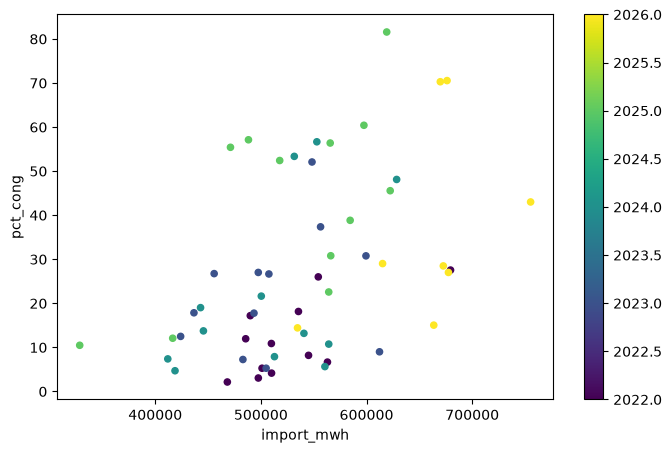

In [208]:
comp = pd.concat({'import_mwh': imp, 'pct_cong': pct}, axis=1).dropna()
print(comp.corr(method='spearman').round(2))
comp.plot.scatter(x='import_mwh', y='pct_cong', c=comp.index.year, cmap='viridis', figsize=(8, 5))

#### Observación:
La región peninsular es importadora neta en todo el periodo: la generación bruta de CFE y PIE queda por debajo de la demanda en todos los meses, con una importación estimada de ~600–850 MW entre 2022 y 2025 que sube a ~850–1,020 MW en 2026. El aumento de 2026 coincide con la mayor congestión, pero el de 2025 no se explica por la importación sola: con una importación similar (~825–835 MW), agosto de 2023 tuvo ~9% de horas congestionadas y agosto de 2025 ~50%, lo que sugiere un cambio en la capacidad efectiva de importación u otras restricciones. La estimación no incluye generación privada, por lo que sobreestima la importación real.

### Congestión del nodo 05CHU-230, ¿Existen efectos de estacionalidad (hora y mes) y balance energético?

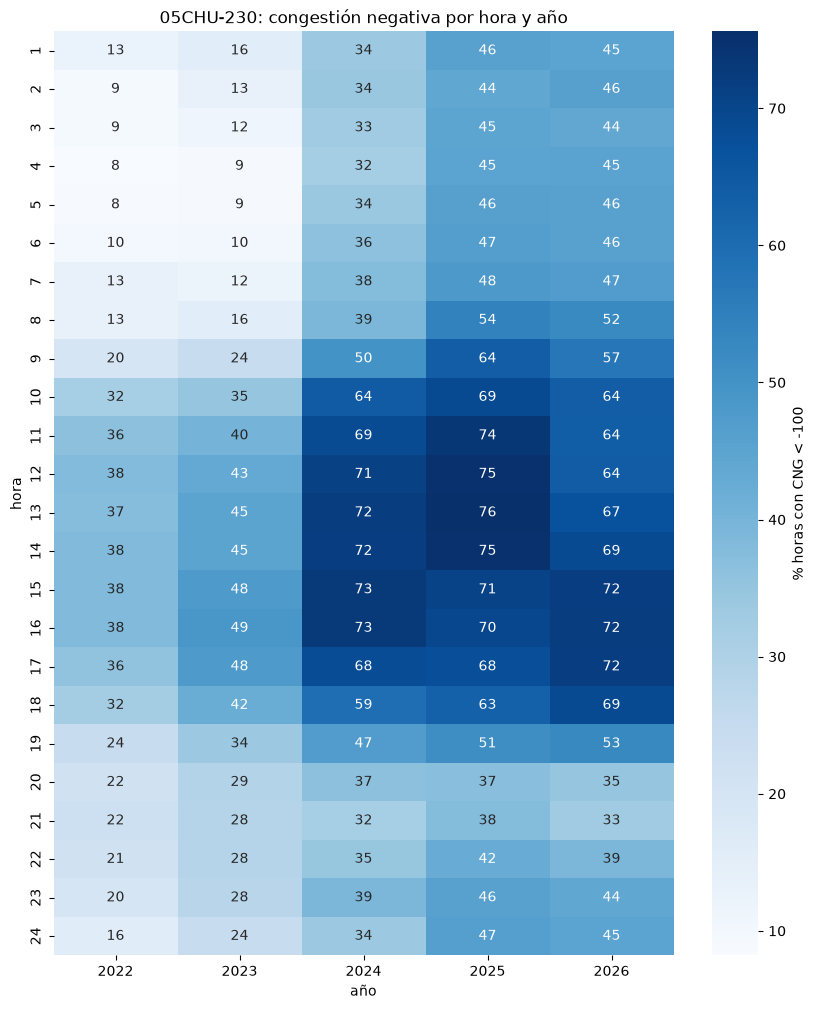

In [201]:
chu = df[df['nodo'] == '05CHU-230'].copy()
   

pct_neg_hora = ((chu['pml_cng'] < -100).groupby([chu['hora'], chu['año']]).mean().mul(100).round(1).unstack('año'))

import seaborn as sns, matplotlib.pyplot as plt
plt.figure(figsize=(10, 12))
sns.heatmap(pct_neg_hora[pct_neg_hora.index.get_level_values('hora') <= 24], annot=True, fmt='.0f', cmap='Blues', cbar_kws={'label': '% horas con CNG < -100'})
plt.title('05CHU-230: congestión negativa por hora y año'); plt.show()

Áreas de demanda usadas: <StringArray>
['NTE']
Length: 1, dtype: str


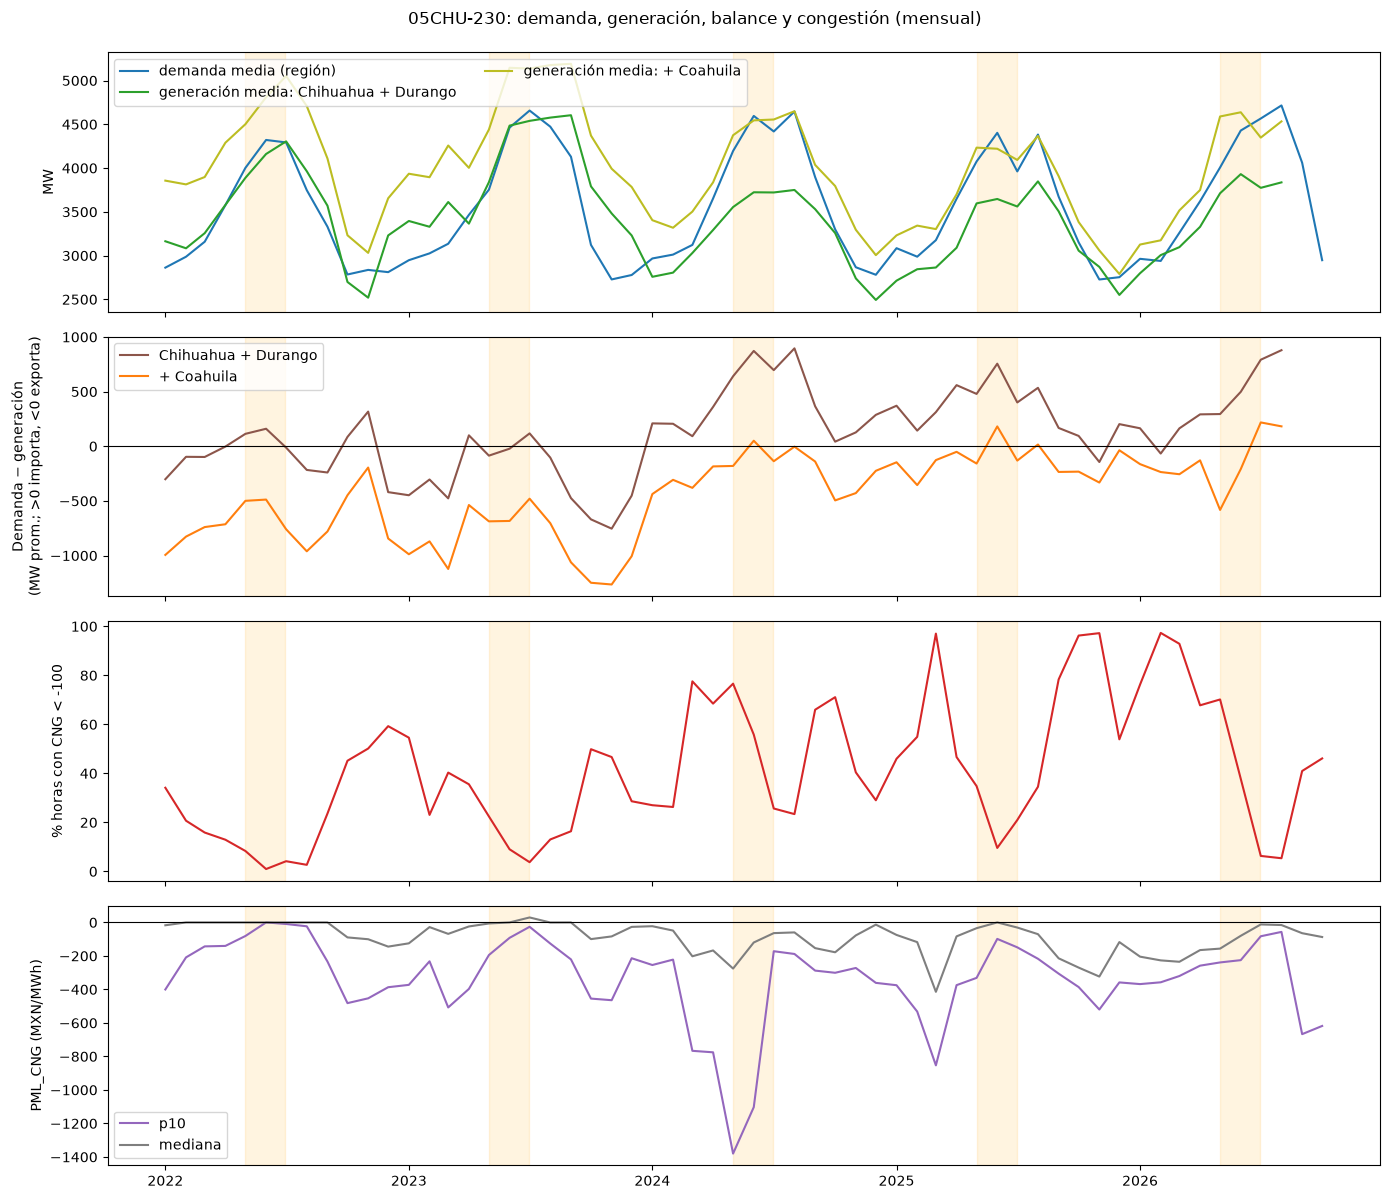

In [202]:
m_chu = grafico_nodo(df, dem, gen, '05CHU-230', area_dem='NTE', exacto=True, signo=-1,
                     estados_gen={'Chihuahua + Durango': ['Chihuahua', 'Durango'],
                                  '+ Coahuila': ['Chihuahua', 'Durango', 'Coahuila']})


### Observaciones

*Región de demanda: Norte (`NTE`). Balance = demanda − generación de CFE y PIE (MW promedio); >0 importa, <0 exporta. La generación no incluye a los privados.*

**Balance.** La región Norte (Chihuahua y Durango) está cerca del equilibrio y no es una exportadora fuerte. La generación de CFE y PIE sigue de cerca a la demanda, y ambas son máximas en verano (≈ 4,300–4,700 MW) y mínimas en invierno (≈ 2,700–3,000 MW). El balance estimado va de ≈ −750 a ≈ +900 MW. En 2022–2023 fue negativo en casi todos los meses fríos (exportación de hasta ≈ 750 MW), y desde 2024 es positivo en casi todos los veranos (hasta ≈ +880 MW en 2024 y 2026): la región importa en los meses de mayor demanda. Si se incluye Coahuila en la generación (de la que solo una parte pertenece a esta región), el balance es negativo casi siempre y se acerca a cero en los veranos (≈ +50 a +220 MW), así que la cifra real está entre las dos curvas.

**Relación con la congestión negativa.** La frecuencia de horas con CNG < −100 MXN/MWh sigue el ciclo anual del balance: es mínima en verano, cuando el balance es más alto (≈ 1–4% en junio–julio de 2022 y 2023, ≈ 10% en junio de 2025 y ≈ 5–6% en julio–agosto de 2026), y llega a ≈ 97% en meses fríos de 2025 y 2026 (marzo de 2025, octubre–noviembre de 2025 y febrero de 2026). Es consistente con que, cuando la demanda de la región es baja, la generación local no encuentra salida y el nodo se abarata respecto al sistema. Aun así, el efecto de la demanda no explica el nivel: de 2022 a 2024 el balance sube (más importación) y a la vez aumenta la congestión negativa (de 16.9% a 51.8% de las horas), al revés de lo que se esperaría si solo dependiera del balance de CFE y PIE.

**Intensidad.** El p10 de PML_CNG suele estar entre ≈ −200 y −500 MXN/MWh y la mediana pasó de ≈ 0 en 2022 a valores negativos de ≈ −100 a −400 desde 2024, lo que indica congestión en más de la mitad de las horas en esos meses. El extremo más profundo (p10 ≈ −1,380 MXN/MWh en mayo de 2024, y ≈ −1,100 en junio) coincide con el episodio de calor y escasez de 2024 y ocurre en meses donde la frecuencia de congestión negativa era baja (≈ 25%): fueron pocas horas, pero muy intensas.

**Interpretación y límites.** Una explicación compatible con los datos es que el aumento de la generación privada, sobre todo solar, que no aparece en la serie de CFE y PIE, y los límites de transmisión para sacar esa energía expliquen el aumento de la congestión negativa aunque el balance de CFE y PIE no cambie en esa dirección. Esto es una hipótesis: para probarla haría falta generación horaria que incluya a los privados. 